# Kinh doanh sách: nghiên cứu mô phỏng có kiểm chứng

**Dữ liệu mô phỏng hoàn toàn; không đại diện thị trường.** Notebook dùng cùng hàm với pipeline. Một dòng là một đơn một đầu sách giả lập. Mọi con số dưới đây được tính khi chạy; phần diễn giải và tài liệu tham khảo đầy đủ nằm trong `report/bao_cao.pdf` và `docs/QUY-TRINH.md`.

Mục tiêu: xây dựng dữ liệu, kiểm chứng làm sạch, trả lời bảy câu hỏi EDA và đánh giá độ nhạy. Không suy ra lợi nhuận, chuyển đổi hay tác động nhân quả. Chạy `python run.py` trước để tạo các dữ liệu và kết quả thí nghiệm.

In [1]:
from pathlib import Path
import sys, json, tempfile
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.data_cleaner import clean
from src.analysis import summarize, evaluate, error_family_performance
from src.visualizer import generate_all_charts
# Charts are rendered into a temporary directory, not into the repository. The committed charts
# come from run.py; regenerating them here would dirty the working tree on any machine whose
# matplotlib build renders a PNG differently, which is every machine of a different platform.
CHART_DIR=Path(tempfile.mkdtemp(prefix='book-sales-charts-'))
pd.set_option('display.max_columns',12)
pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
raw=pd.read_csv(ROOT/'data/raw/book_sales_raw.csv')
catalog=pd.read_csv(ROOT/'data/reference/catalog.csv')
print('Dòng/cột raw:',raw.shape,'; số mã sách trong catalog:',len(catalog))
display(raw.head())

Dòng/cột raw: (6660, 16) ; số mã sách trong catalog: 300


,raw_row_id,ma_sach,ten_sach,the_loai,tac_gia,nha_xuat_ban,...,kenh_ban,ma_dong,ma_don,giam_gia_niem_yet,gia_ban,so_luong
0,R000001,BK0279,Sách mô phỏng 279,Nuôi dạy con,Tác giả giả lập 03,NXB giả lập 08,...,Sàn C,L005831,O005831,25,123000,3.000
1,R000002,BK0058,Sách mô phỏng 058,Văn học,Tác giả giả lập 07,NXB giả lập 08,...,Sàn B,L003316,O003316,5,76000,2.000
2,R000003,BK0001,Sách mô phỏng 001,Kỹ năng sống,Tác giả giả lập 04,NXB giả lập 03,...,Sàn B,L000753,O000753,25,113000,10.000
3,R000004,BK0007,Sách mô phỏng 007,KỸ NĂNG SỐNG,Tác giả giả lập 04,NXB giả lập 03,...,Sàn A,L003188,O003188,15,61000,4.000
4,R000005,BK0152,Sách mô phỏng 152,Khoa học công nghệ,Tác giả giả lập 12,NXB giả lập 08,...,Sàn A,L005320,O005320,20,83000,3.000


## 1. Khảo sát dữ liệu thô

Đếm riêng bản sao cùng mã và ô thiếu. Số mã lặp không tự quyết định số dòng bị xóa: cần xem nội dung có giống nhau sau chuẩn hóa hay không.

In [2]:
display(pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum()}))
print('Mã dòng lặp:',raw.ma_dong.duplicated().sum())

,dtype,missing
raw_row_id,object,0
ma_sach,object,0
ten_sach,object,0
the_loai,object,0
tac_gia,object,132
nha_xuat_ban,object,134
nam_xuat_ban,float64,138
gia_goc,int64,0
diem_danh_gia,float64,135
ngay_ban,object,0


Mã dòng lặp: 160


## 2. Làm sạch dùng chung quy tắc

Hàm chỉ nhận raw và catalog, không nhận truth hoặc nhãn lỗi. Quy trình: chuẩn hóa → phục hồi có căn cứ → gộp bản sao giống nhau → cách ly xung đột → gắn cờ IQR → tạo đặc trưng. Chi tiết và lý do từng bước ở `docs/QUY-TRINH.md`.

In [3]:
df,stages,quarantine,changes,lineage=clean(raw,catalog)
display(stages)
display(quarantine.groupby('ly_do').size().rename('so_dong'))
assert len(lineage)==len(raw)==lineage.raw_row_id.nunique()
assert not df.ma_dong.duplicated().any()
display(changes.head(10))

,buoc,so_dong,o_thieu,ma_dong_lap
0,01. Nạp dữ liệu,6660,539,160
1,02. Chuẩn hóa và khôi phục có căn cứ,6660,1,160
2,03. Gộp bản sao cùng mã và cùng nội dung,6505,1,5
3,04. Cách ly bất thường và xung đột,6478,1,0


ly_do
conflicting_line_id        10
invalid_required_fields     7
quantity_needs_review      10
Name: so_dong, dtype: int64

,raw_row_id,ma_dong,cot,truoc,sau
0,R000004,L003188,the_loai,KỸ NĂNG SỐNG,Kỹ năng sống
1,R000008,L000234,the_loai,KINH TẾ - QUẢN TRỊ,Kinh tế - Quản trị
2,R000048,L003784,the_loai,GIÁO DỤC - NGOẠI NGỮ,Giáo dục - Ngoại ngữ
3,R000063,L001600,the_loai,KINH TẾ - QUẢN TRỊ,Kinh tế - Quản trị
4,R000068,L000240,the_loai,KỸ NĂNG SỐNG,Kỹ năng sống
5,R000095,L000474,the_loai,TÂM LÝ HỌC,Tâm lý học
6,R000103,L000231,the_loai,TRUYỆN TRANH,Truyện tranh
7,R000106,L004468,the_loai,TÂM LÝ HỌC,Tâm lý học
8,R000158,L003335,the_loai,GIÁO DỤC - NGOẠI NGỮ,Giáo dục - Ngoại ngữ
9,R000164,L005134,the_loai,KỸ NĂNG SỐNG,Kỹ năng sống


## 3. Đối soát kết quả và phục hồi

Chỉ từ bước đánh giá mới đọc dữ liệu chuẩn. So sánh theo mã dòng; kiểm tra cả tính đúng của dòng giữ lại và chênh lệch tổng kỳ do cách ly.

In [4]:
stored=pd.read_csv(ROOT/'data/processed/book_sales_clean.csv')
pd.testing.assert_frame_equal(df.astype('string').reset_index(drop=True),stored.astype('string').reset_index(drop=True))
truth=pd.read_csv(ROOT/'data/reference/ground_truth.csv')
errors=pd.read_csv(ROOT/'data/audit/injected_errors.csv')
recovery,validation=evaluate(truth,df,raw,errors)
display(recovery)
display(pd.Series(validation,name='gia_tri'))
tables,metrics=summarize(df)
published=json.loads((ROOT/'results/metrics.json').read_text(encoding='utf8'))
assert metrics==published['metrics']
display(pd.Series(metrics,name='gia_tri'))

,cot,so_khop,so_so_sanh,ty_le_khop
0,gia_ban,6468,6478,0.998
1,so_luong,6472,6478,0.999
2,doanh_thu,6462,6478,0.998
3,diem_danh_gia,6478,6478,1.000
4,nam_xuat_ban,6478,6478,1.000
5,tac_gia,6477,6478,1.000
6,nha_xuat_ban,6478,6478,1.000
7,the_loai,6473,6478,0.999


truth_revenue                2,978,555,000.000
clean_revenue                3,067,680,000.000
relative_revenue_error_pct               2.992
retained_pct                            99.662
quarantine_precision                     1.000
quarantine_recall                        0.021
retained_revenue_error          99,657,000.000
unresolved_missing                       0.000
Name: gia_tri, dtype: float64

lines                        6,478.000
books                          301.000
orders                       6,478.000
revenue              3,067,680,000.000
quantity                    32,100.000
average_unit_price          95,566.355
yoy_pct                         -4.009
rating_qty_r                     0.012
rating_book_qty_r                0.105
discount_qty_r                   0.098
rating_known                 6,478.000
good_rating_pct                 74.220
iqr_flags                      184.000
Name: gia_tri, dtype: float64

## 4. Hiệu năng phát hiện theo họ lỗi

Đây là phần trả lời trực tiếp cho phê bình về con số 100%/100%. Một tỷ lệ gộp không cho biết quy tắc mạnh ở đâu; tách theo họ lỗi mới thấy giới hạn thật của phương pháp. Cột `con_sai` là số dòng mang lỗi vẫn nằm trong tập phân tích và vẫn khác dữ liệu chuẩn — thước đo thiệt hại, không phải tỷ lệ phát hiện.

In [5]:
families=error_family_performance(truth,df,raw,errors)
stored_families=pd.read_csv(ROOT/'results/error_family_performance.csv')
pd.testing.assert_frame_equal(families.reset_index(drop=True),stored_families.reset_index(drop=True))
display(families)
print('Tổng hợp:',families.attrs['aggregate'])
print('Tỷ lệ phát hiện gộp trên toàn bộ họ lỗi: %.1f%%'%(100*families.recall.mean()))
print('Số dòng mang lỗi vẫn còn sai trong tập sạch:',int(families.con_sai.sum()))
# Charts are generated here, before any of them is displayed, so the notebook does not depend on
# a later cell having run first.
exp=pd.read_csv(ROOT/'results/sensitivity_runs.csv')
null=pd.read_csv(ROOT/'results/null_distribution.csv')
nullstats=pd.read_csv(ROOT/'results/null_summary.csv')
missing=pd.read_csv(ROOT/'results/missing_sensitivity.csv')
coverage=pd.read_csv(ROOT/'results/catalog_coverage.csv')
generate_all_charts(df,tables,exp,CHART_DIR,null=null,families=families,missing=missing,coverage=coverage,metrics=metrics)

,ho_loi,n_cai,n_cach_ly,n_danh_dau,recall,n_lot,con_sai,ty_le_sot_sai,phat_hien_duoc,ghi_chu
0,qty_scale,8,2,0,0.250,6,6,0.750,partly,Số cuốn nhân 10^k; phần lớn vẫn nằm dưới ngưỡn...
1,qty_negative,5,5,0,1.000,0,0,0.000,yes,Số cuốn âm; vi phạm miền giá trị.
2,qty_fractional,3,3,0,1.000,0,0,0.000,yes,Số cuốn không nguyên; vi phạm miền giá trị.
3,price_reset,4,0,0,0.000,4,4,1.000,no,Giá bán đặt lại bằng giá gốc; mất chiết khấu n...
4,price_swap,10,4,0,0.400,6,6,0.600,partly,Hoán vị giá bán giữa hai dòng; chỉ lộ khi giá ...
5,date_swap,8,3,0,0.375,5,5,0.625,partly,"Đảo ngày/tháng khi biểu diễn được, còn lại lùi..."
6,genre_mislabel,5,0,0,0.000,5,5,1.000,no,Thể loại hợp lệ nhưng sai; không thể phát hiện...
7,catalog_missing,6,0,6,1.000,6,6,1.000,yes,Mã sách không có trong danh mục; phát hiện bằn...


Tổng hợp: {'n_cai': 49, 'n_cach_ly': 17, 'n_danh_dau': 6, 'recall': 0.469388, 'con_sai': 32}
Tỷ lệ phát hiện gộp trên toàn bộ họ lỗi: 50.3%
Số dòng mang lỗi vẫn còn sai trong tập sạch: 32


Các họ tạo ra giá trị vẫn hợp lệ — giá đặt lại bằng giá gốc, giá hoán vị, ngày đảo, thể loại sai — không thể phát hiện bằng miền giá trị. Bài giữ lại các dòng đó và công bố ảnh hưởng, thay vì dựng quy tắc đọc dữ liệu chuẩn để xóa chúng.

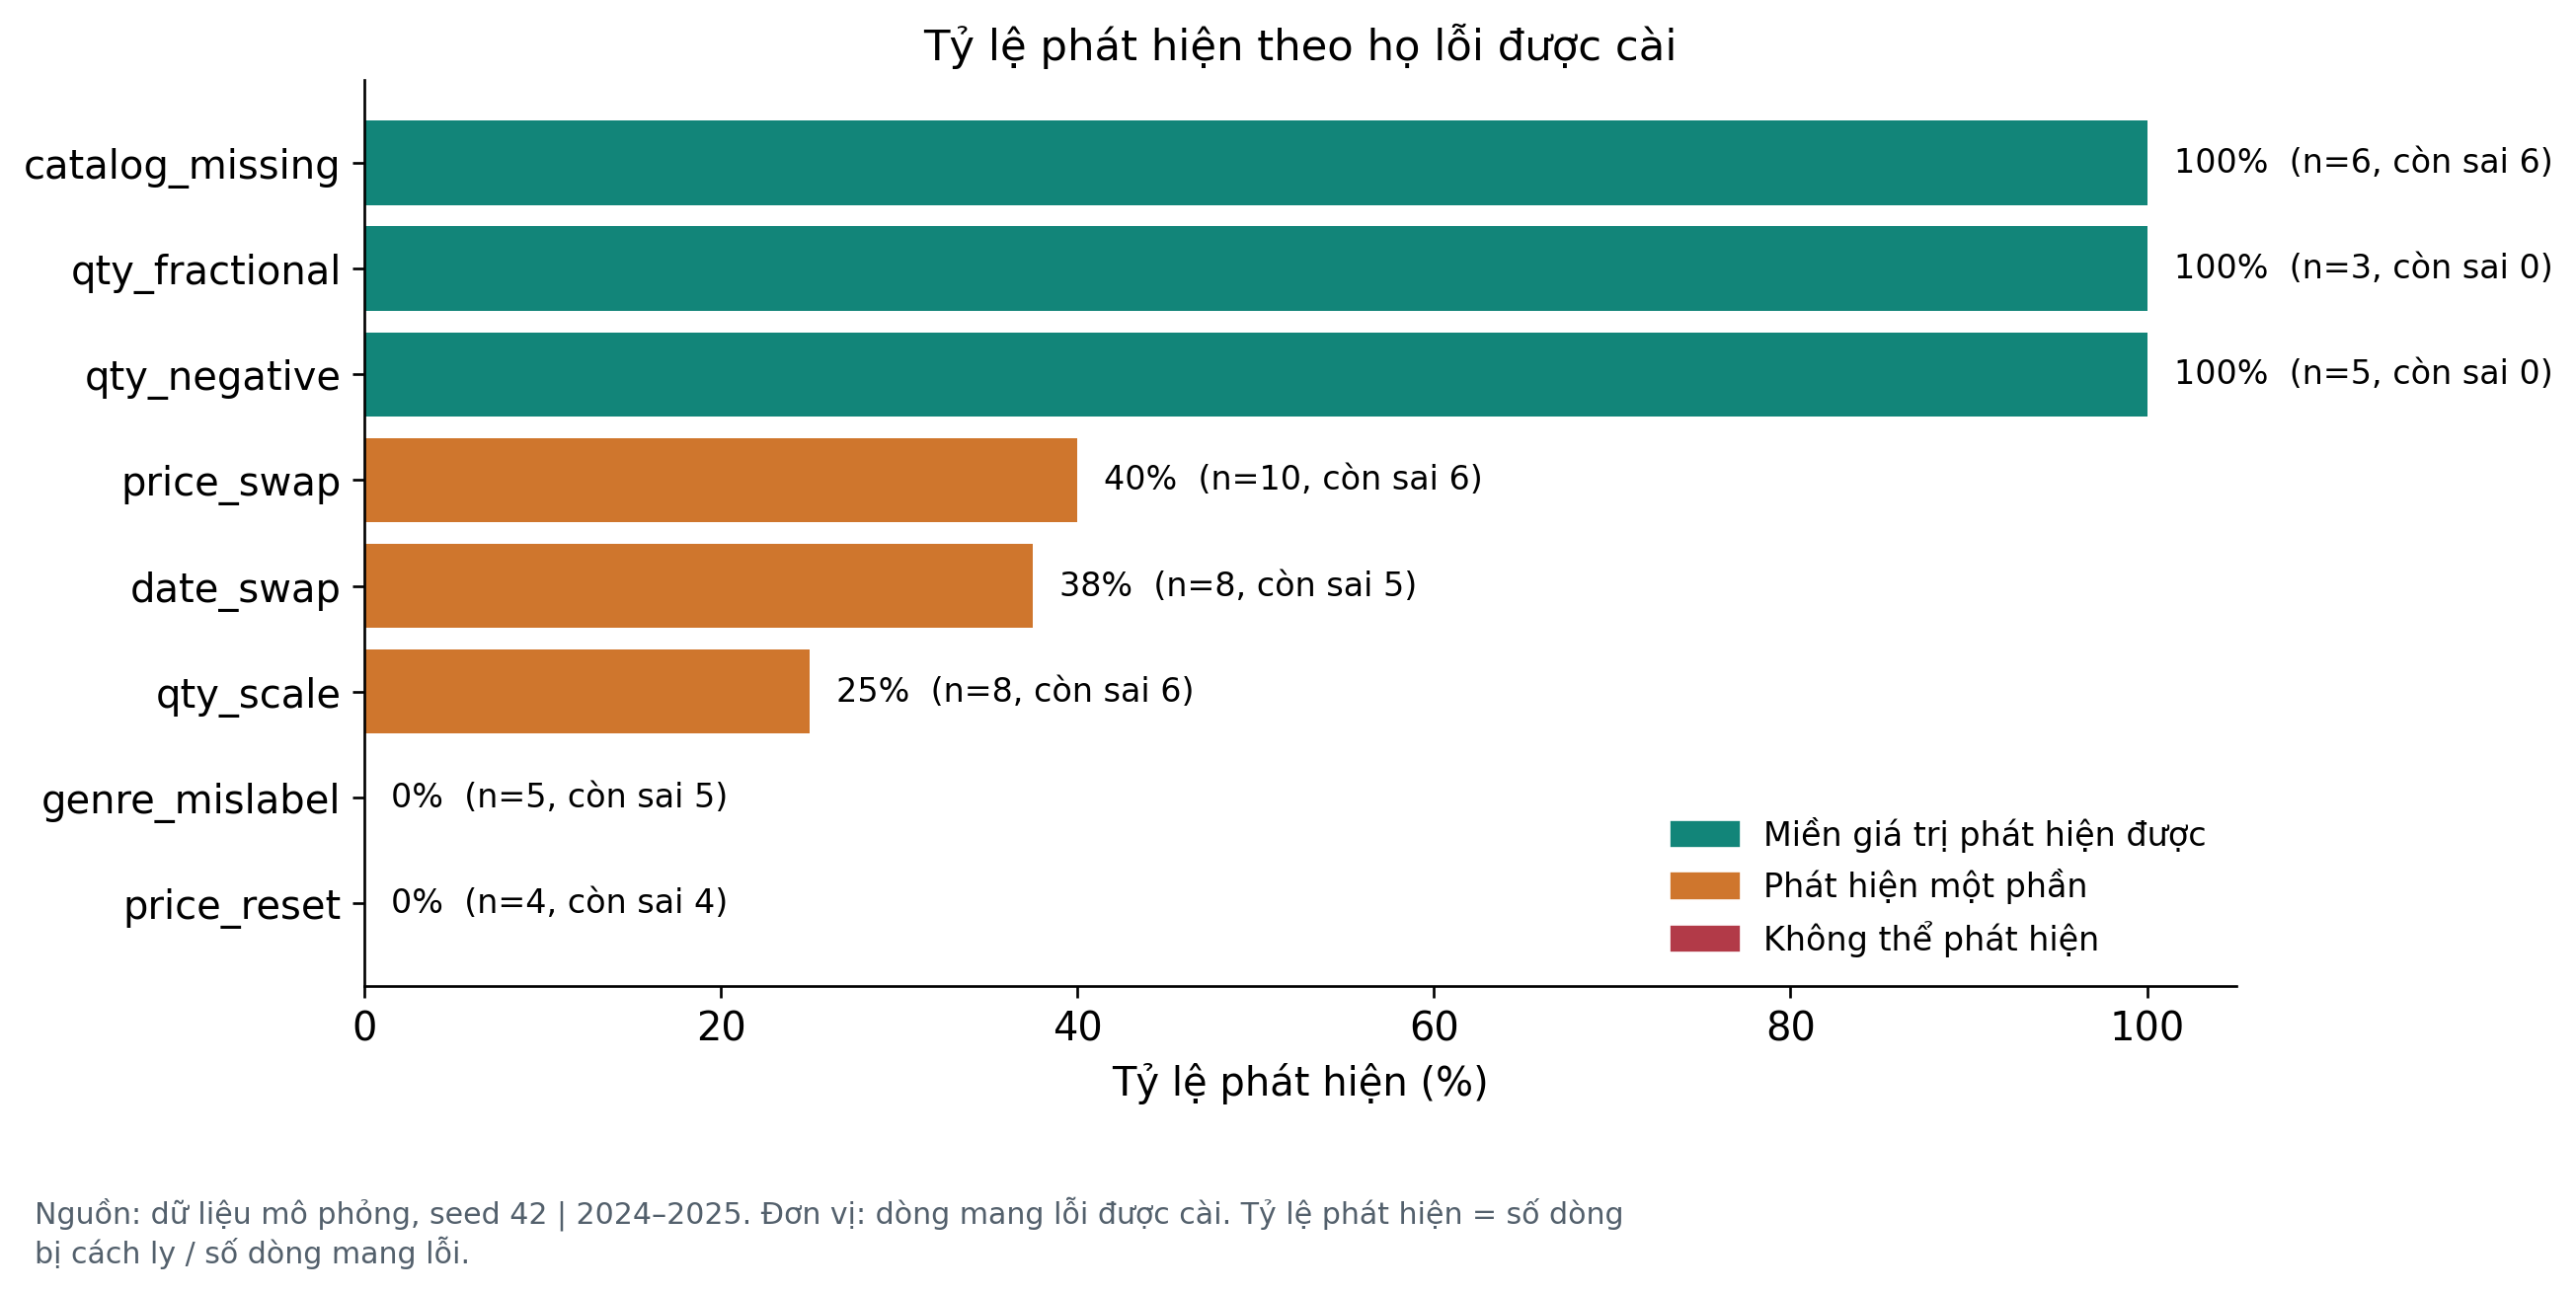

In [6]:
display(Image(filename=str(CHART_DIR/'09_error_family.png')))

## 5. EDA cơ bản và các bảng kết quả

Các biến phụ thuộc theo định nghĩa: giá trị bán hàng = giá × lượng; giảm giá thực tế từ giá bán/giá gốc. Pearson chỉ mô tả tương quan, không là bằng chứng nhân quả.

In [7]:
display(tables['describe'])
display(tables['discount'])

,bien,count,mean,std,min,25%,50%,75%,max
0,gia_goc,"6,478.000","131,824.020","64,487.954","45,000.000","86,000.000","117,000.000","156,000.000","350,000.000"
1,gia_ban,"6,478.000","109,188.484","56,477.470","27,000.000","69,000.000","96,000.000","134,000.000","350,000.000"
2,giam_gia_thuc_te,"6,478.000",17.254,12.379,0.000,5.316,15.193,25.333,68.627
3,so_luong,"6,478.000",4.955,12.511,1.000,3.000,4.000,6.000,800.000
4,doanh_thu,"6,478.000","473,553.566","966,681.183","38,000.000","255,250.000","392,000.000","572,000.000","54,400,000.000"
5,diem_danh_gia,"6,478.000",4.217,0.496,2.500,3.900,4.300,4.600,4.900


,nhom_giam_gia,n,median_qty,mean_qty,total_revenue
0,0–5%,1734,3.000,3.480,715351000
1,>15–25%,1400,5.000,5.680,722431000
2,>25–40%,1557,6.000,6.688,826947000
3,>5–15%,1787,4.000,4.309,802951000


## 6. Bảy câu hỏi kinh doanh trong kịch bản

Tất cả đồ thị được tạo lại từ chính `df` vừa làm sạch. Kết quả độ nhạy đã tính bởi pipeline được đọc từ CSV; notebook không âm thầm chạy lại hàng trăm mô phỏng.

### Thể loại

So sánh giá trị và số cuốn trên hai trục riêng. Thứ hạng chịu ảnh hưởng trọng số thể loại đã đặt, không là thị phần thị trường.

,the_loai,doanh_thu,so_luong,so_dong,ty_trong
3,Kỹ năng sống,645230000,6184,1313,21.033
9,Văn học,549686000,5678,1191,17.919
2,Kinh tế - Quản trị,481912000,5320,971,15.709
6,Thiếu nhi,414045000,4519,867,13.497
8,Tâm lý học,306191000,3150,575,9.981
0,Giáo dục - Ngoại ngữ,190774000,2090,452,6.219
1,Khoa học công nghệ,154955000,1620,356,5.051
7,Truyện tranh,139320000,1445,304,4.542
4,Lịch sử - Triết học,108433000,1200,259,3.535
5,Nuôi dạy con,77134000,894,190,2.514


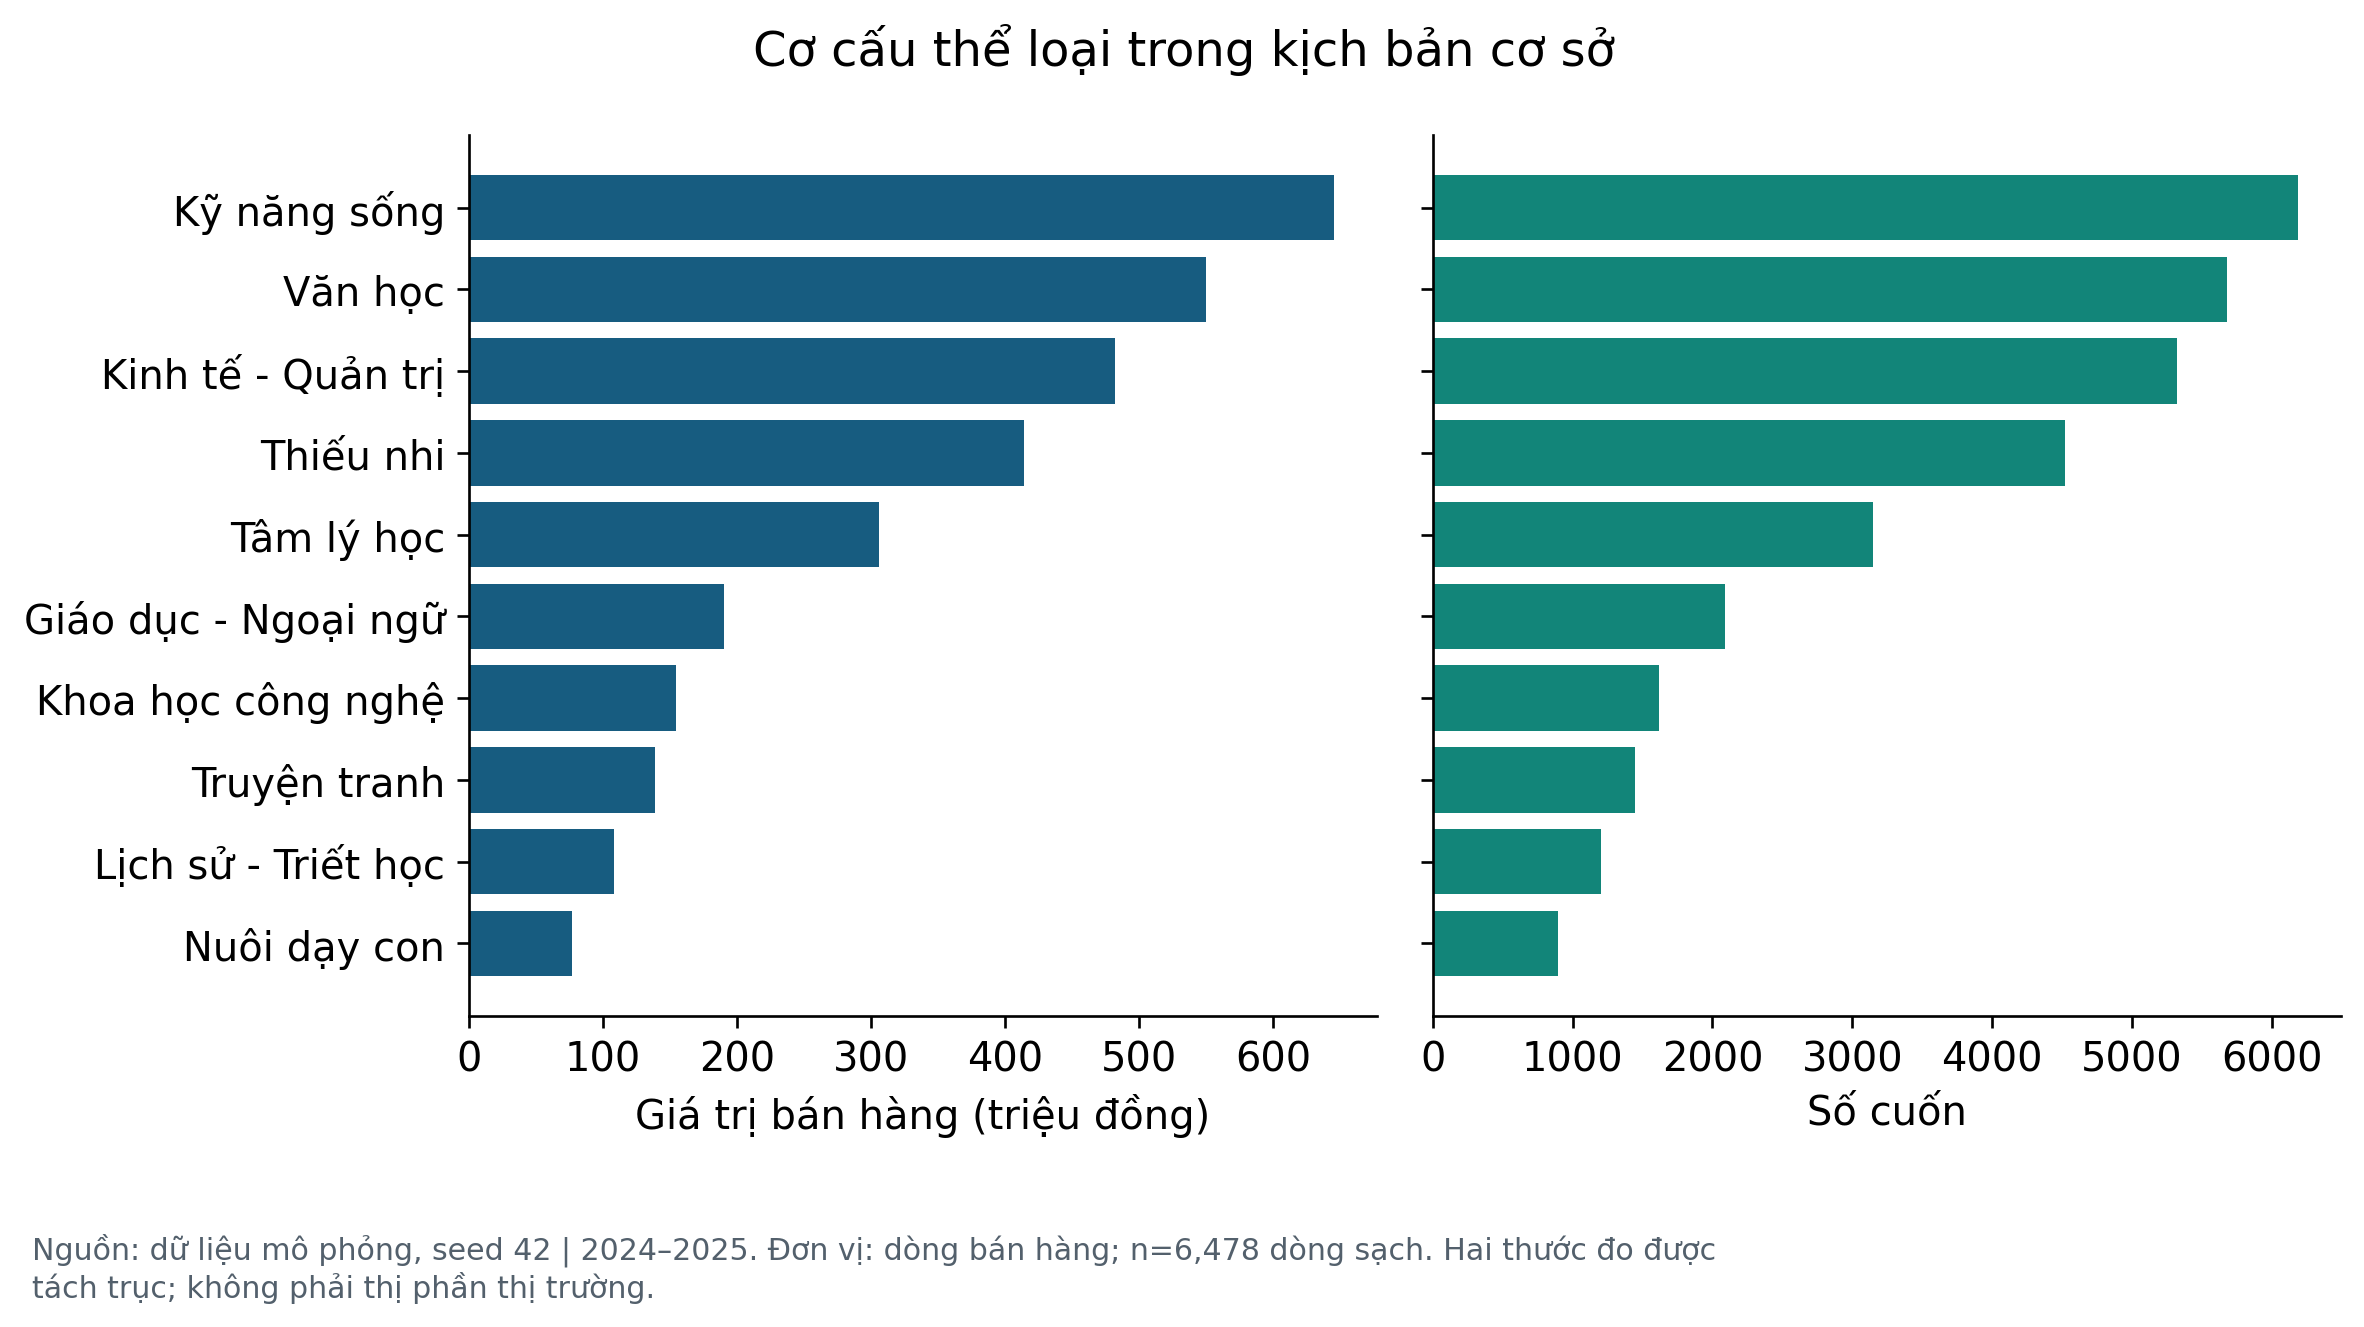

In [8]:
display(tables['genre'].head(24))
display(Image(filename=str(CHART_DIR/'01_genre.png')))

### Mã sách

Xếp theo mã sách, không theo tên hoặc tác giả thiếu. Đọc kèm số dòng và số cuốn để nhận biết ảnh hưởng mua số lượng lớn.

,ma_sach,ten_sach,doanh_thu,so_luong,so_dong,diem_danh_gia
71,BK0072,Sách mô phỏng 072,68009000,1015,40,4.400
8,BK0009,Sách mô phỏng 009,47701000,429,49,4.100
134,BK0135,Sách mô phỏng 135,41017000,267,26,3.700
15,BK0016,Sách mô phỏng 016,34880000,220,56,4.400
94,BK0095,Sách mô phỏng 095,32188000,462,29,4.500
50,BK0051,Sách mô phỏng 051,31588000,164,44,4.400
12,BK0013,Sách mô phỏng 013,30823000,173,48,3.800
21,BK0022,Sách mô phỏng 022,29828000,119,46,4.700
75,BK0076,Sách mô phỏng 076,28772000,106,40,4.400
10,BK0011,Sách mô phỏng 011,27564000,257,50,4.400


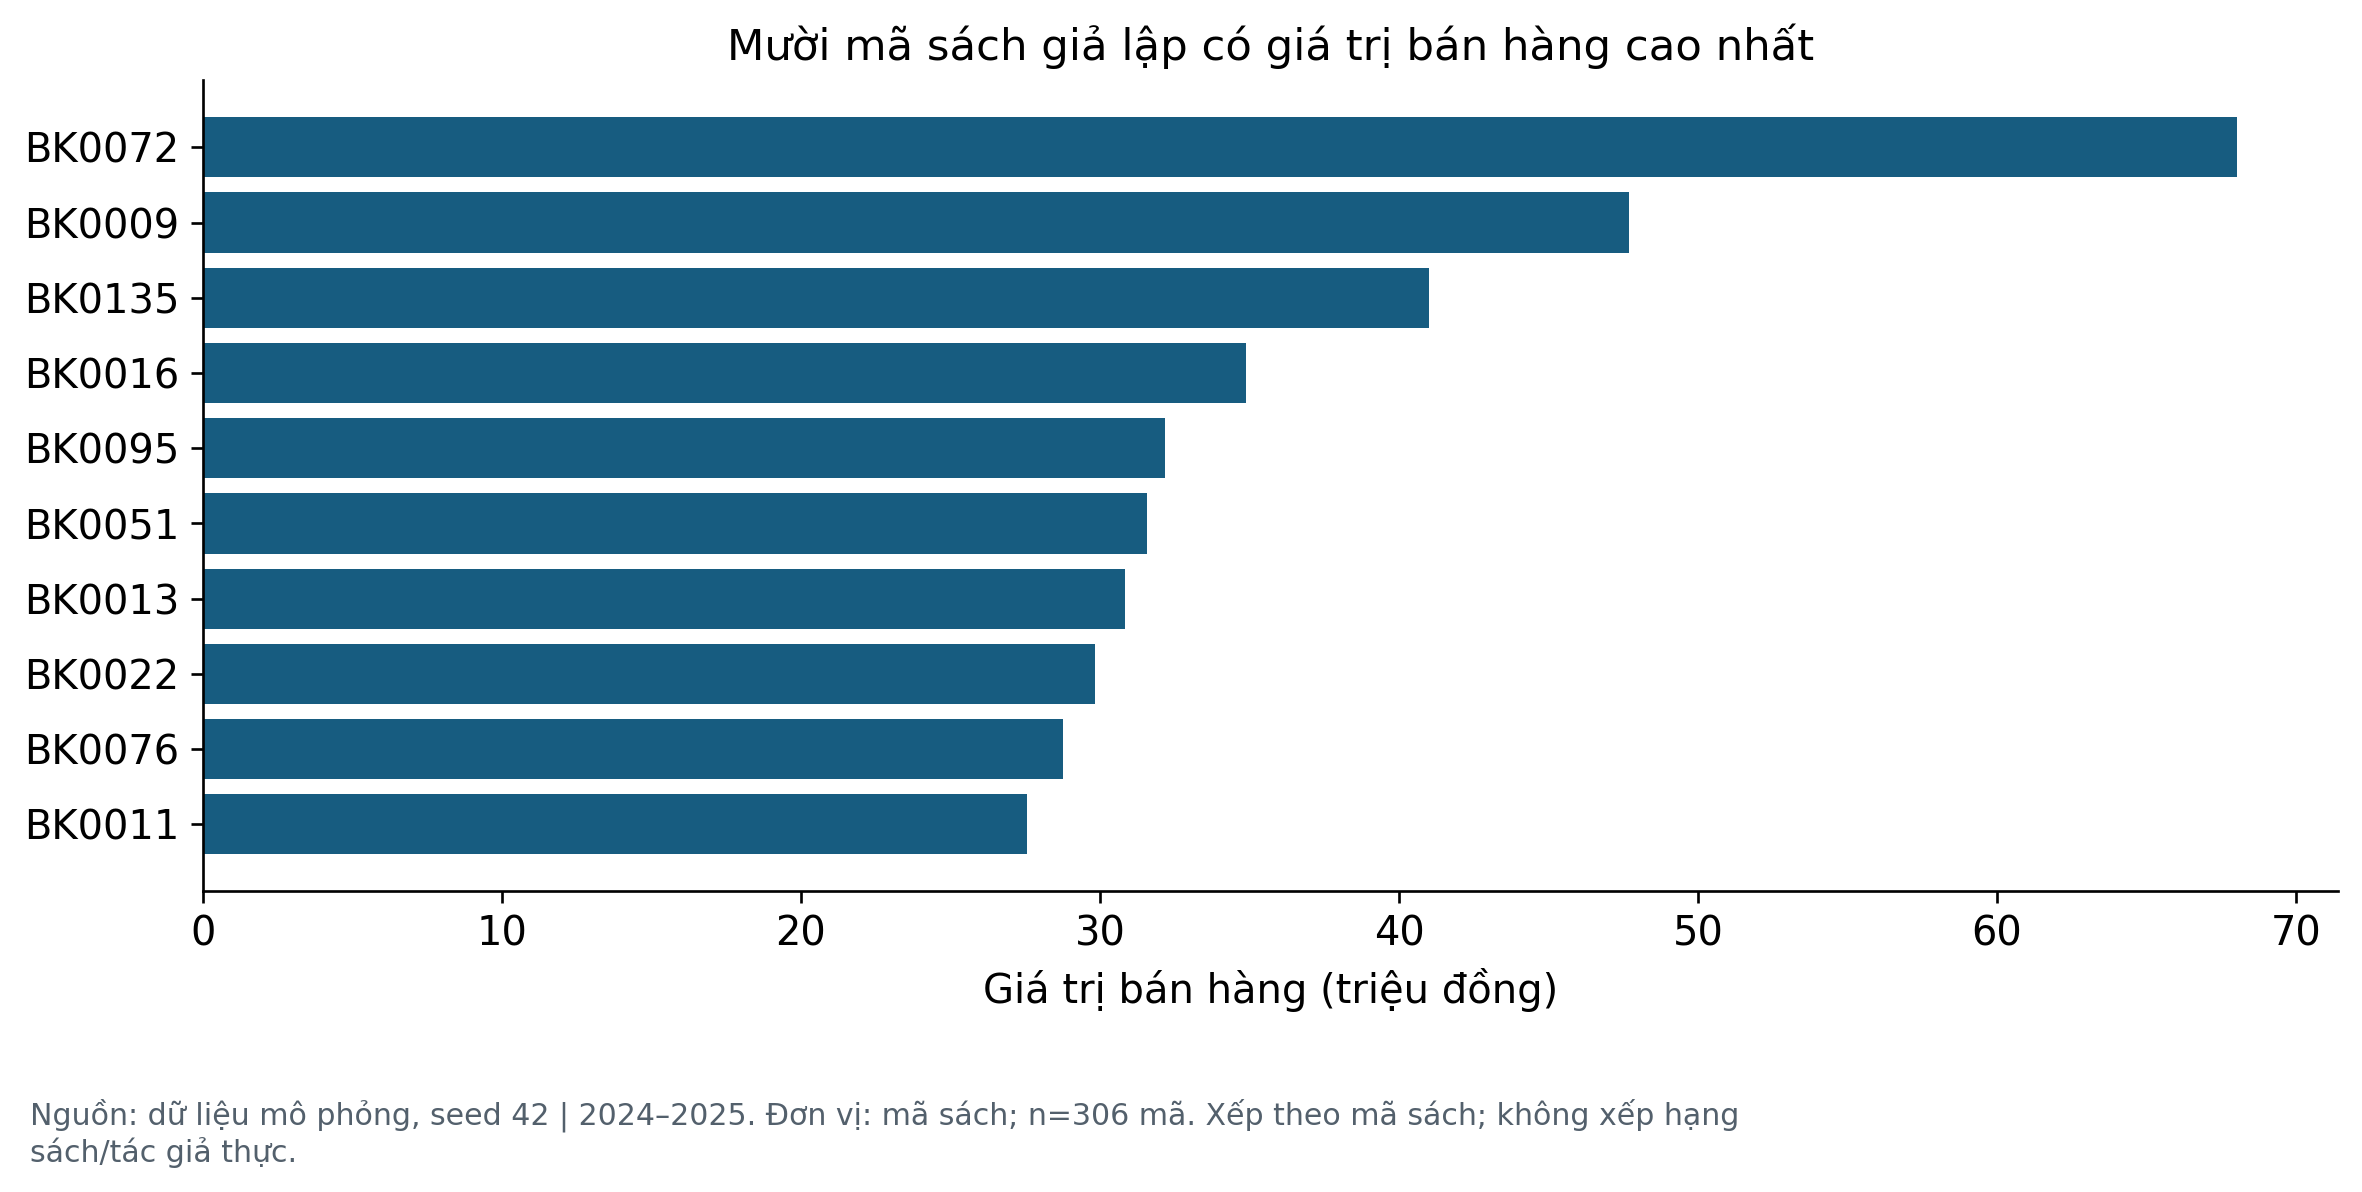

In [9]:
display(tables['books'].head(24))
display(Image(filename=str(CHART_DIR/'02_books.png')))

### Theo tháng

Hệ số mùa vụ đã được cài. Tăng trưởng giữa hai năm có thể do ngẫu nhiên; không gọi là tăng trưởng thị trường.

,thang_nam,doanh_thu,so_luong,so_dong,ty_trong
10,2024-11,221716000,2485,277,7.227
23,2025-12,167145000,1668,283,5.449
22,2025-11,166891000,1896,277,5.440
11,2024-12,145992000,1580,244,4.759
1,2024-02,143379000,1352,239,4.674
7,2024-08,136879000,1406,279,4.462
20,2025-09,136595000,1500,267,4.453
4,2024-05,136187000,1392,298,4.439
8,2024-09,133954000,1420,252,4.367
18,2025-07,129777000,1376,291,4.230


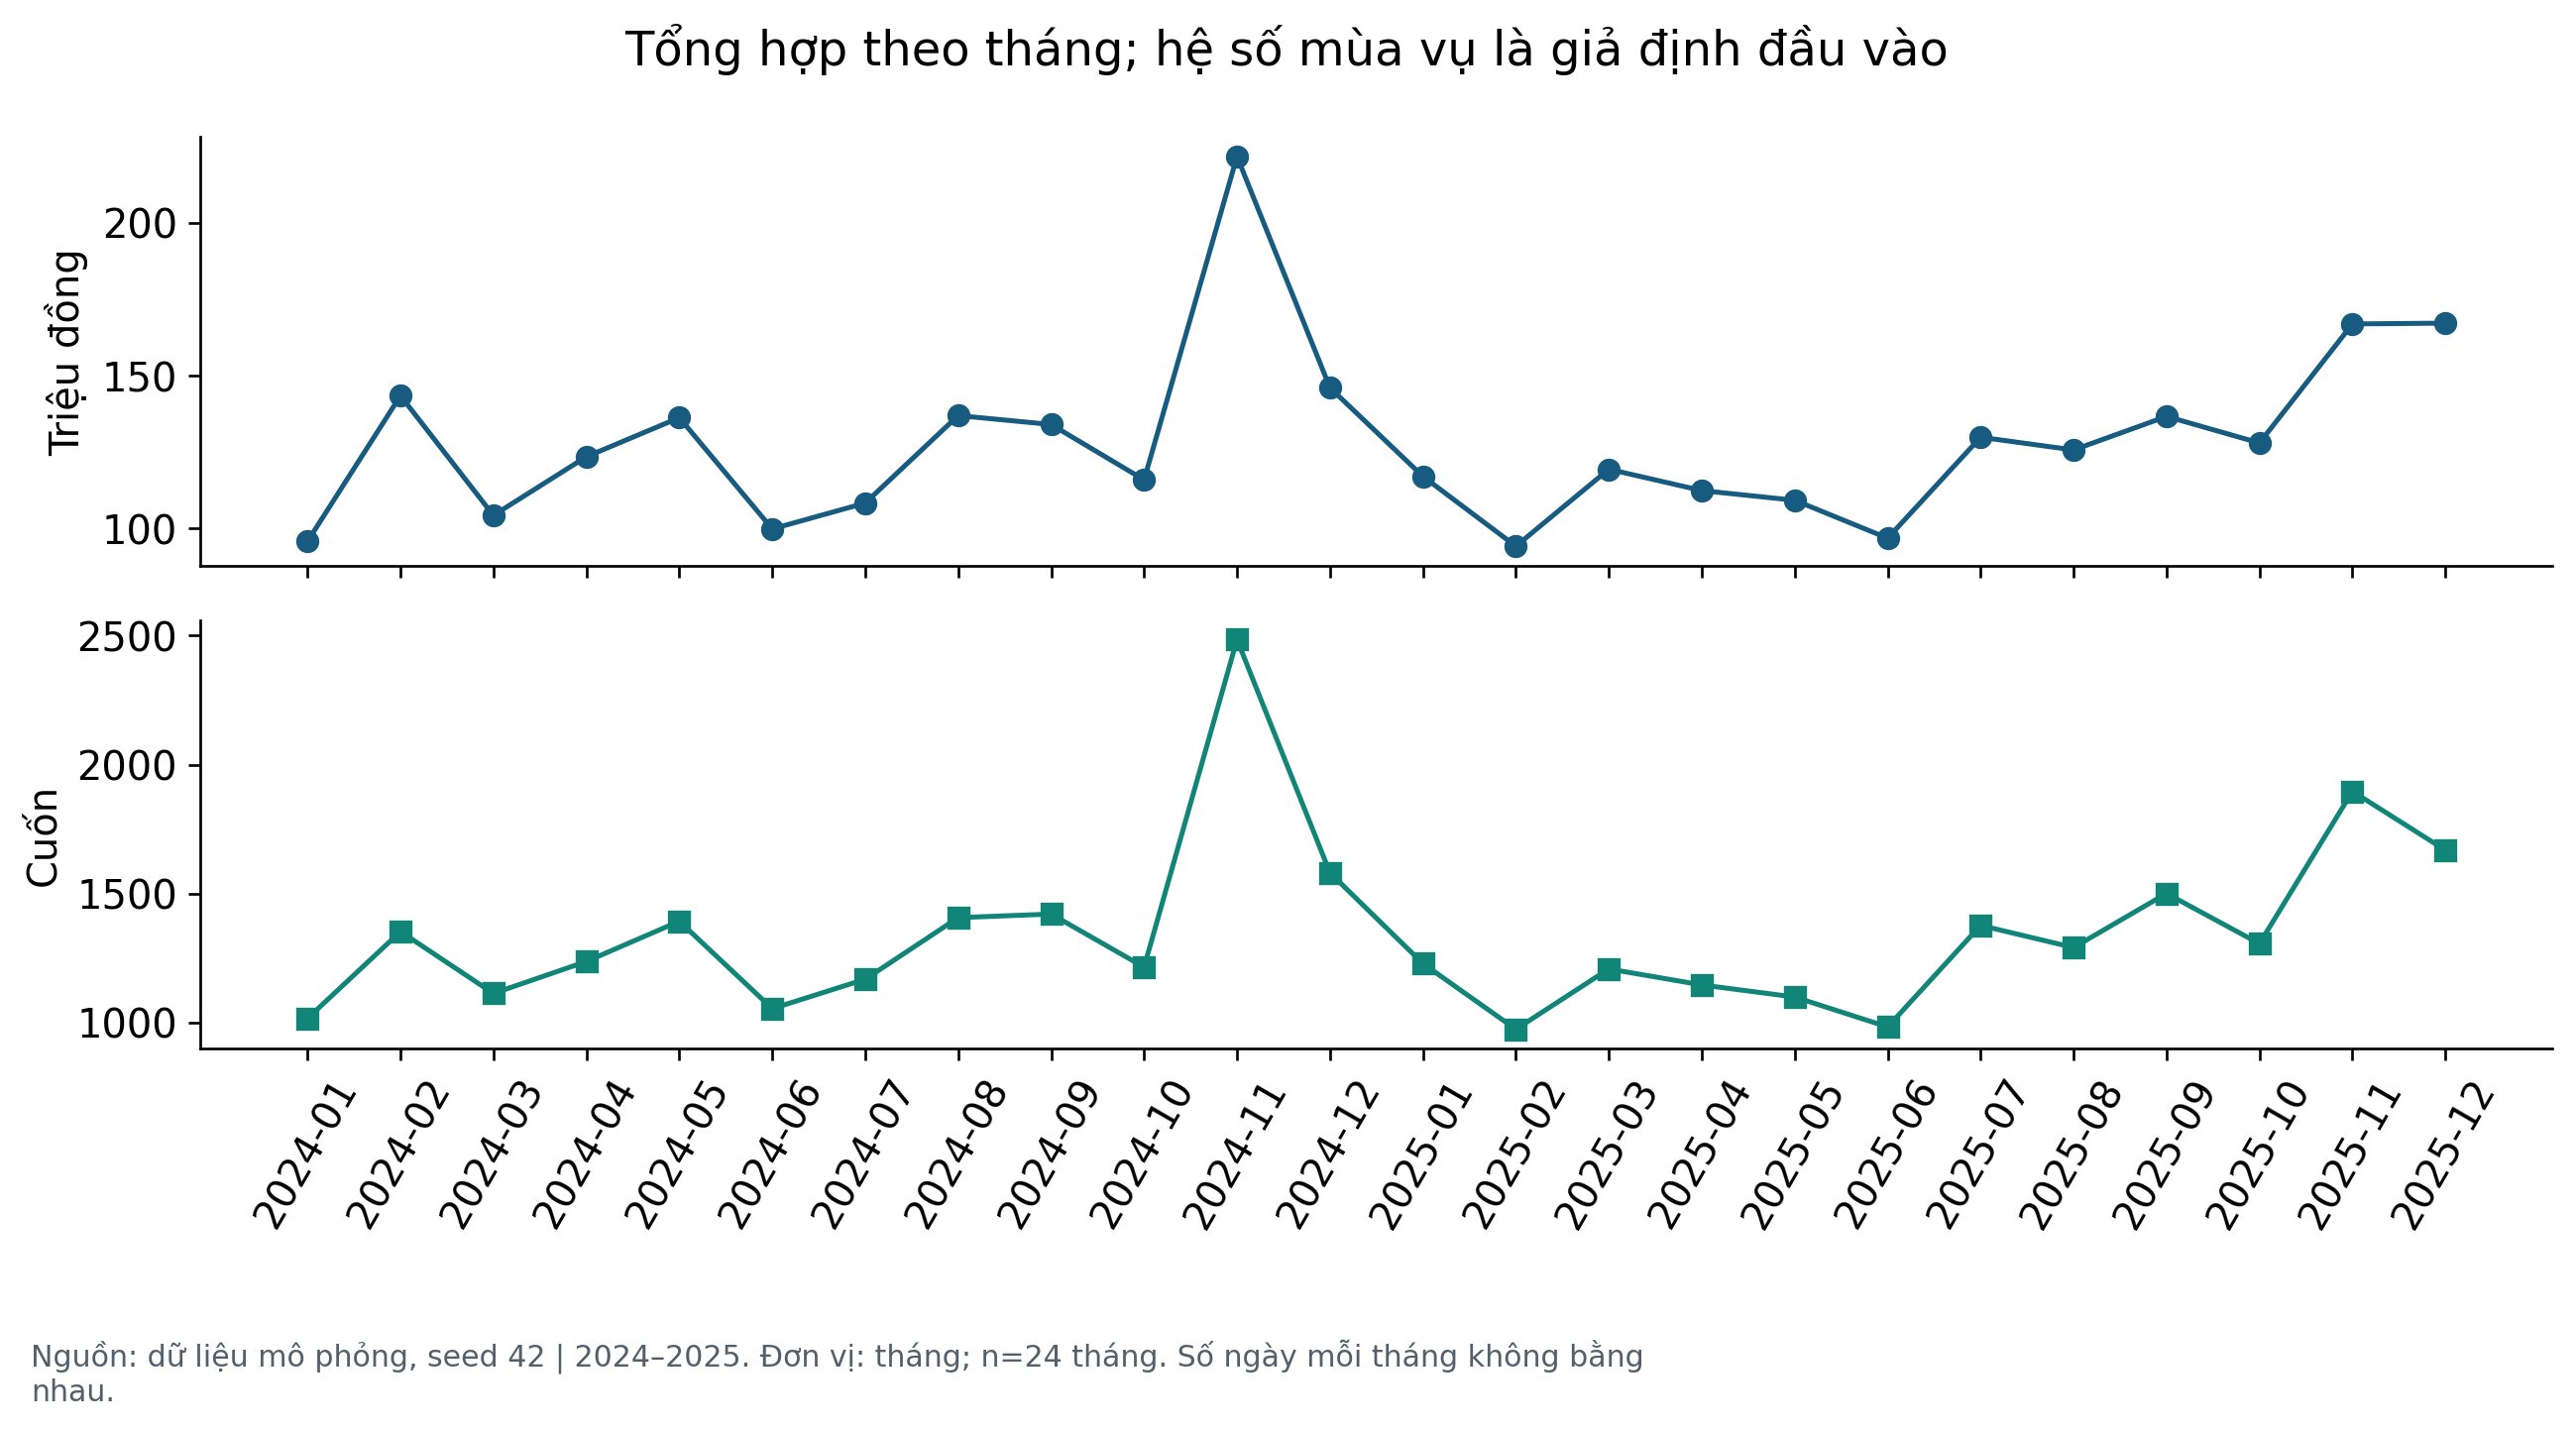

In [10]:
display(tables['month'].head(24))
display(Image(filename=str(CHART_DIR/'03_month.png')))

### Giá và giảm giá

Nhóm dùng mức giảm niêm yết; tương quan dùng mức thực tế. Giá và giảm giá đã có trong công thức sinh lượng.

,nhom_giam_gia,n,median_qty,mean_qty,total_revenue
0,0–5%,1734,3.000,3.480,715351000
1,>15–25%,1400,5.000,5.680,722431000
2,>25–40%,1557,6.000,6.688,826947000
3,>5–15%,1787,4.000,4.309,802951000


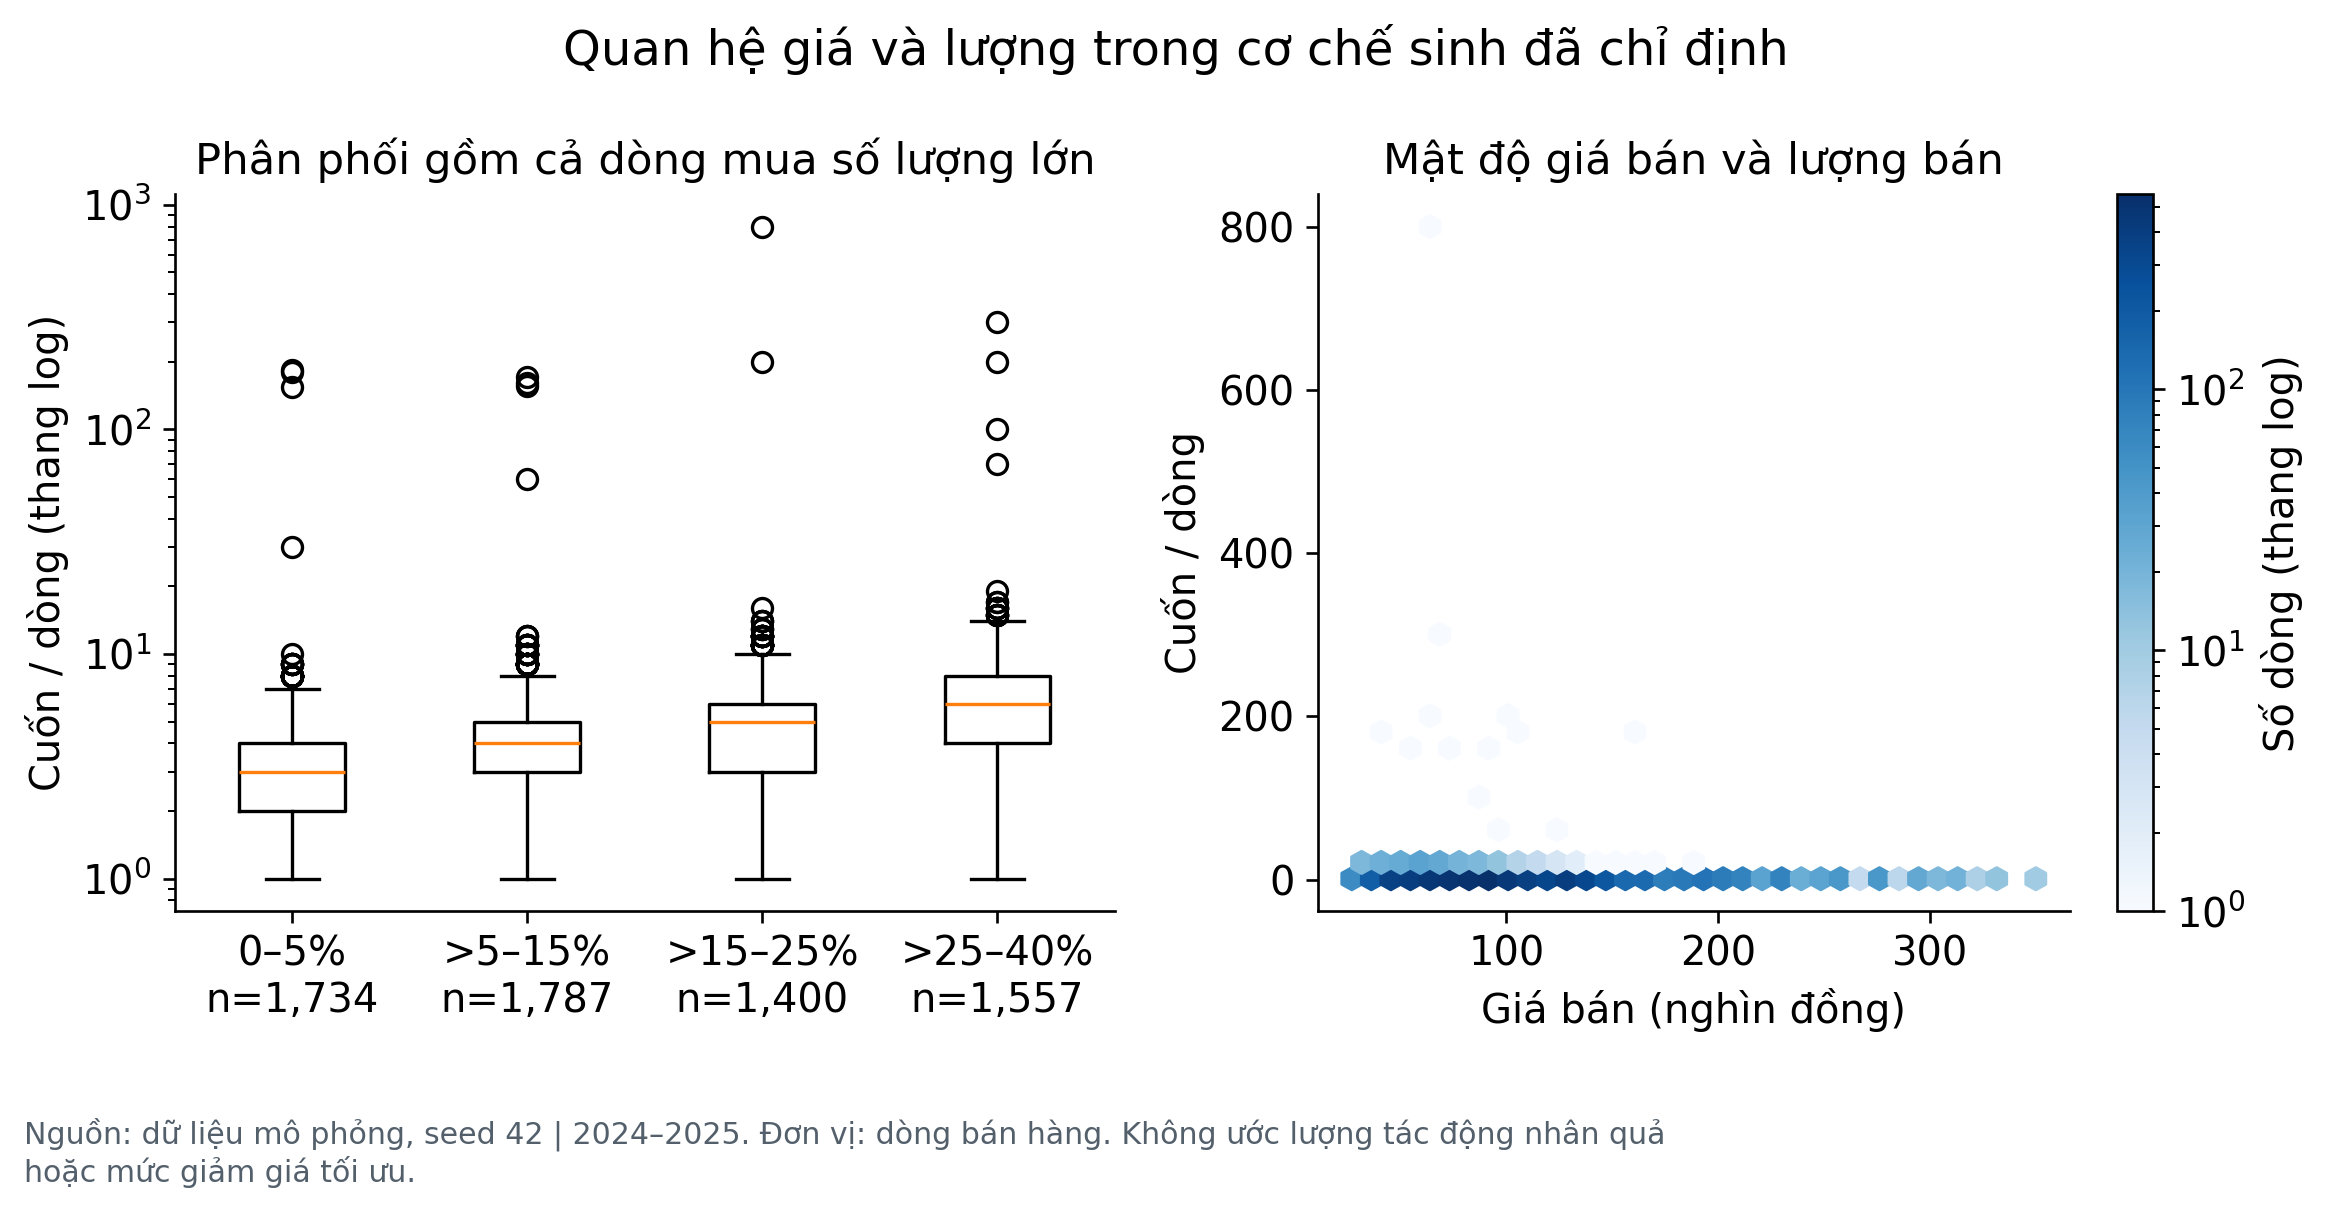

In [11]:
display(tables['discount'].head(24))
display(Image(filename=str(CHART_DIR/'04_discount.png')))

### Điểm và lượng theo sách

Điểm giả lập được cố định trước kỳ bán. Tổng hợp lên cấp sách để tránh đánh đồng dòng giao dịch với một sách độc lập.

,ma_sach,ten_sach,doanh_thu,so_luong,so_dong,diem_danh_gia
71,BK0072,Sách mô phỏng 072,68009000,1015,40,4.400
8,BK0009,Sách mô phỏng 009,47701000,429,49,4.100
134,BK0135,Sách mô phỏng 135,41017000,267,26,3.700
15,BK0016,Sách mô phỏng 016,34880000,220,56,4.400
94,BK0095,Sách mô phỏng 095,32188000,462,29,4.500
50,BK0051,Sách mô phỏng 051,31588000,164,44,4.400
12,BK0013,Sách mô phỏng 013,30823000,173,48,3.800
21,BK0022,Sách mô phỏng 022,29828000,119,46,4.700
75,BK0076,Sách mô phỏng 076,28772000,106,40,4.400
10,BK0011,Sách mô phỏng 011,27564000,257,50,4.400


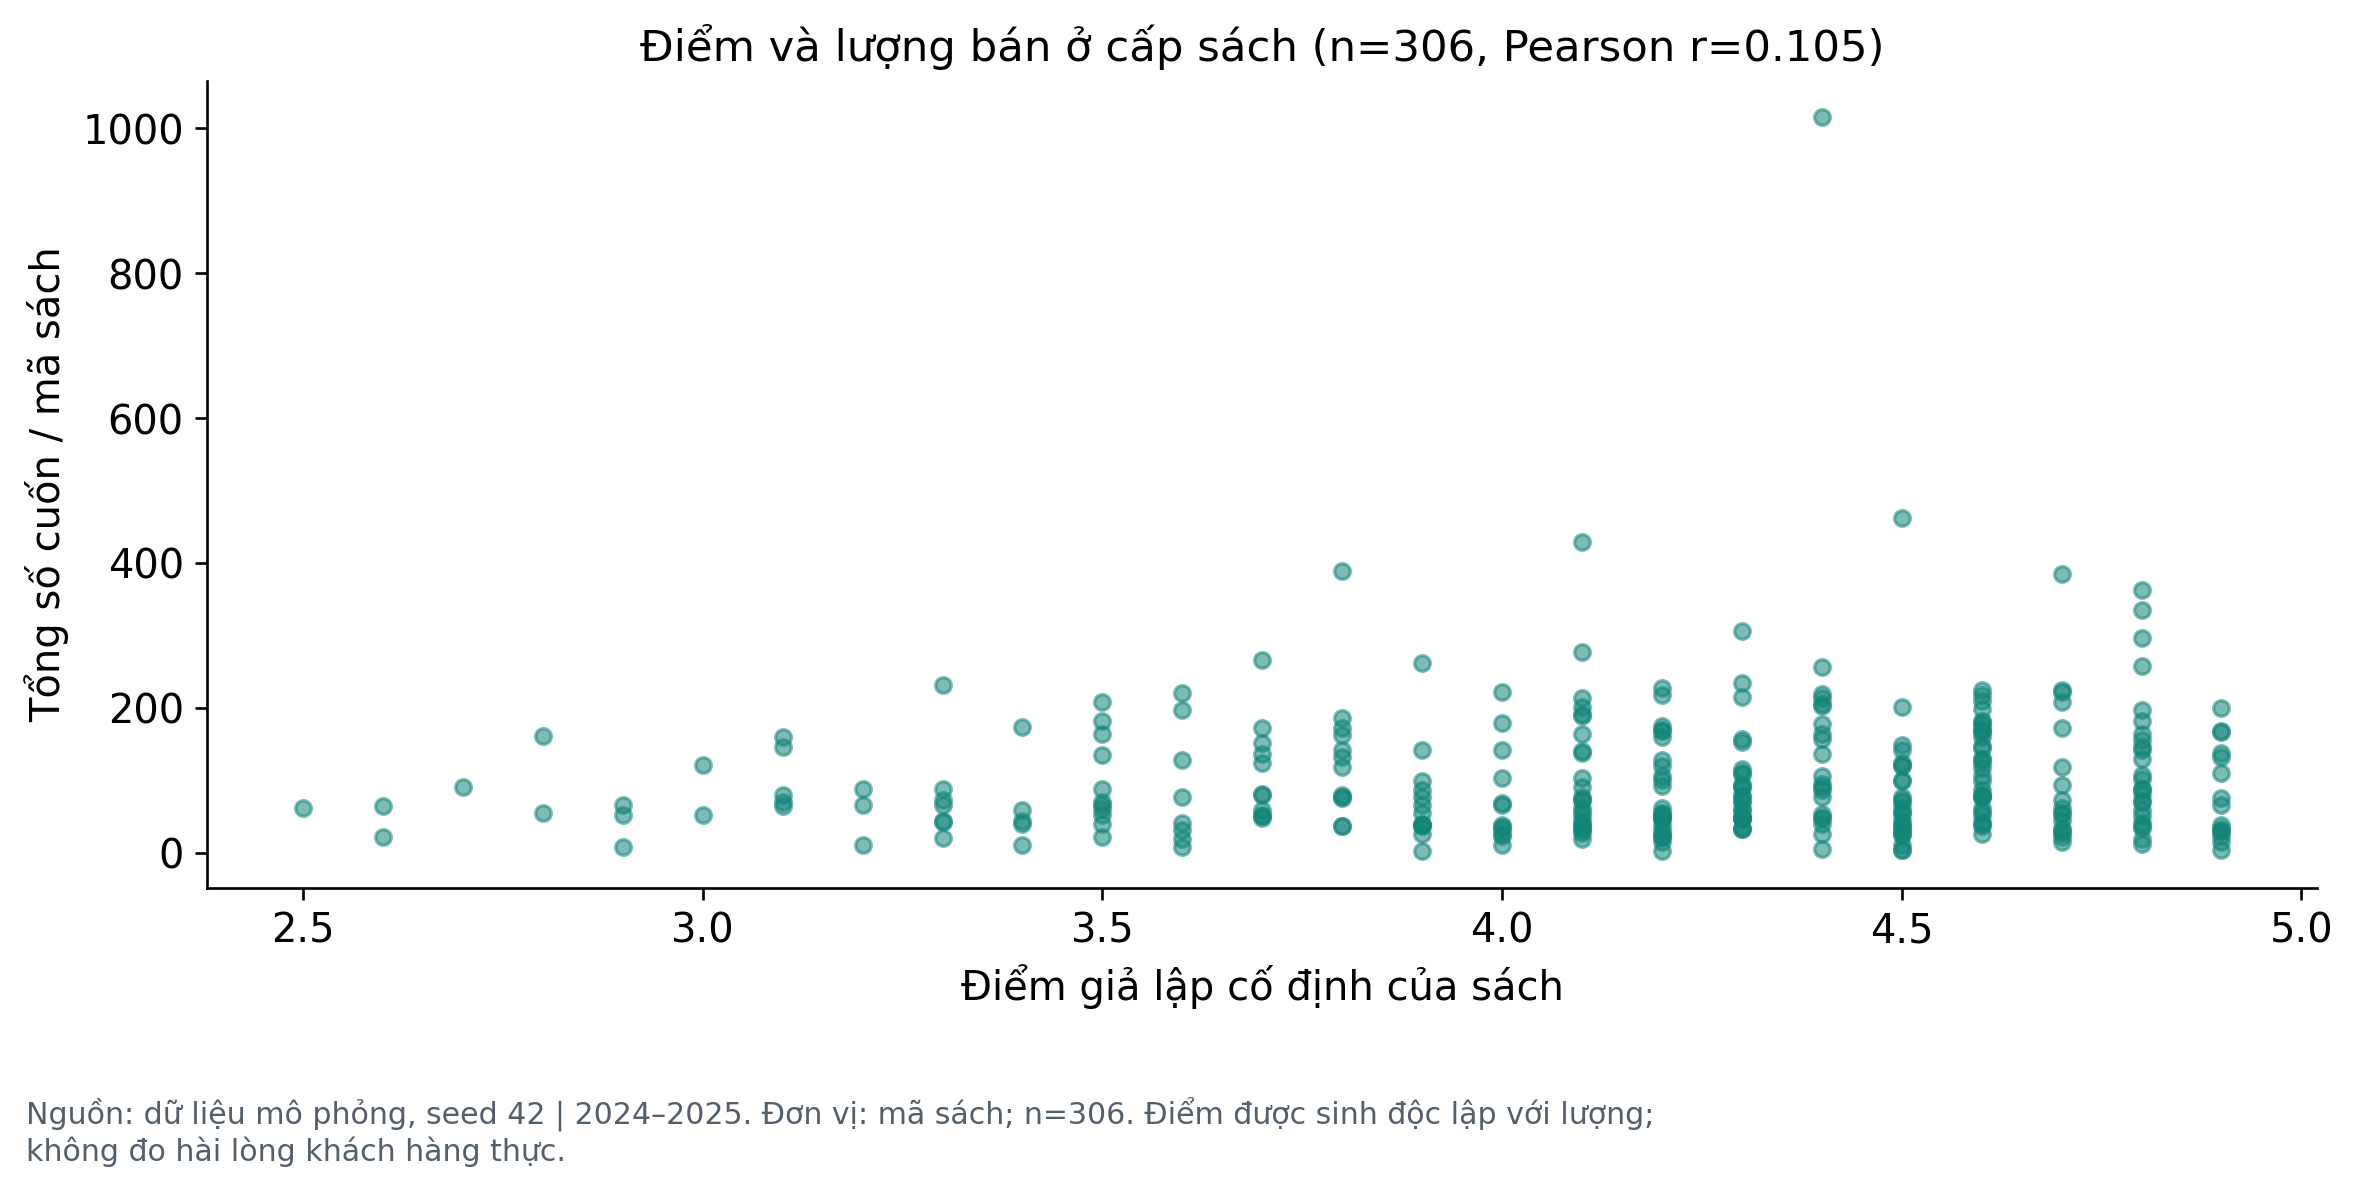

In [12]:
display(tables['books'].head(24))
display(Image(filename=str(CHART_DIR/'05_rating.png')))

### Tương quan

Biến được tính từ nhau có tương quan theo định nghĩa. Không suy ra tối ưu doanh thu hoặc nhân quả từ ma trận.

,gia_goc,gia_ban,giam_gia_thuc_te,so_luong,doanh_thu,diem_danh_gia
gia_goc,1.000,0.946,-0.014,-0.073,0.108,0.058
gia_ban,0.946,1.000,-0.303,-0.096,0.087,0.053
giam_gia_thuc_te,-0.014,-0.303,1.000,0.098,0.046,0.007
so_luong,-0.073,-0.096,0.098,1.000,0.940,0.012
doanh_thu,0.108,0.087,0.046,0.940,1.000,0.017
diem_danh_gia,0.058,0.053,0.007,0.012,0.017,1.000


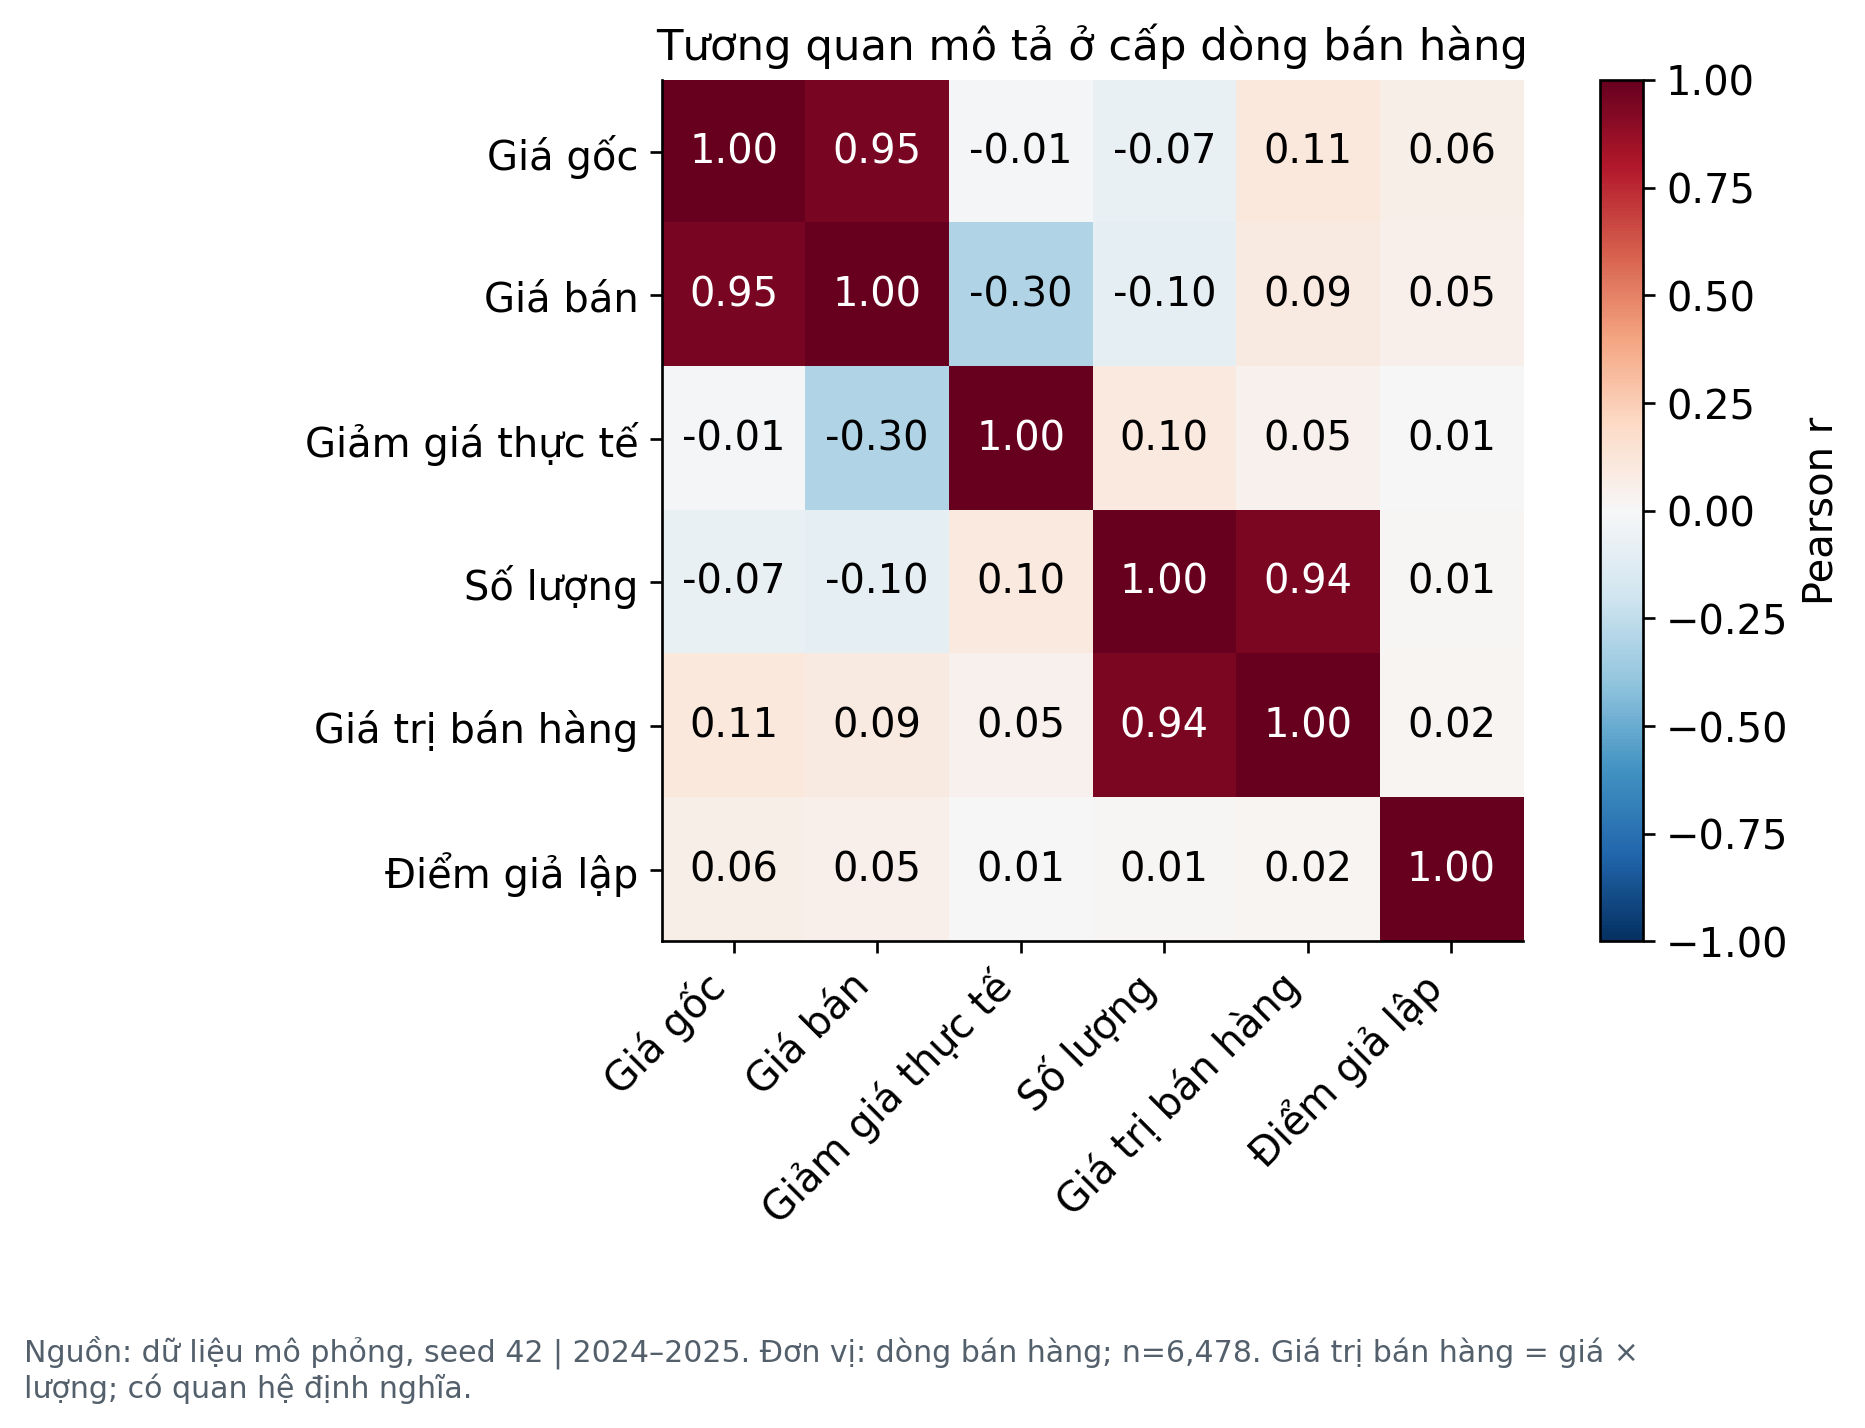

In [13]:
display(tables['correlation'].head(24))
display(Image(filename=str(CHART_DIR/'06_correlation.png')))

### Kênh và phân khúc

Tỷ trọng có mẫu số toàn bộ tập sạch; không có số thị phần thực. Dashboard thay mẫu số khi lọc.

,kenh_ban,doanh_thu,so_luong,so_dong,ty_trong
1,Sàn A,1140848000,12451,2260,37.189
2,Sàn B,626572000,6842,1346,20.425
3,Sàn C,540465000,5792,1169,17.618
0,Cửa hàng,470741000,4415,1012,15.345
4,Website,289054000,2600,691,9.423


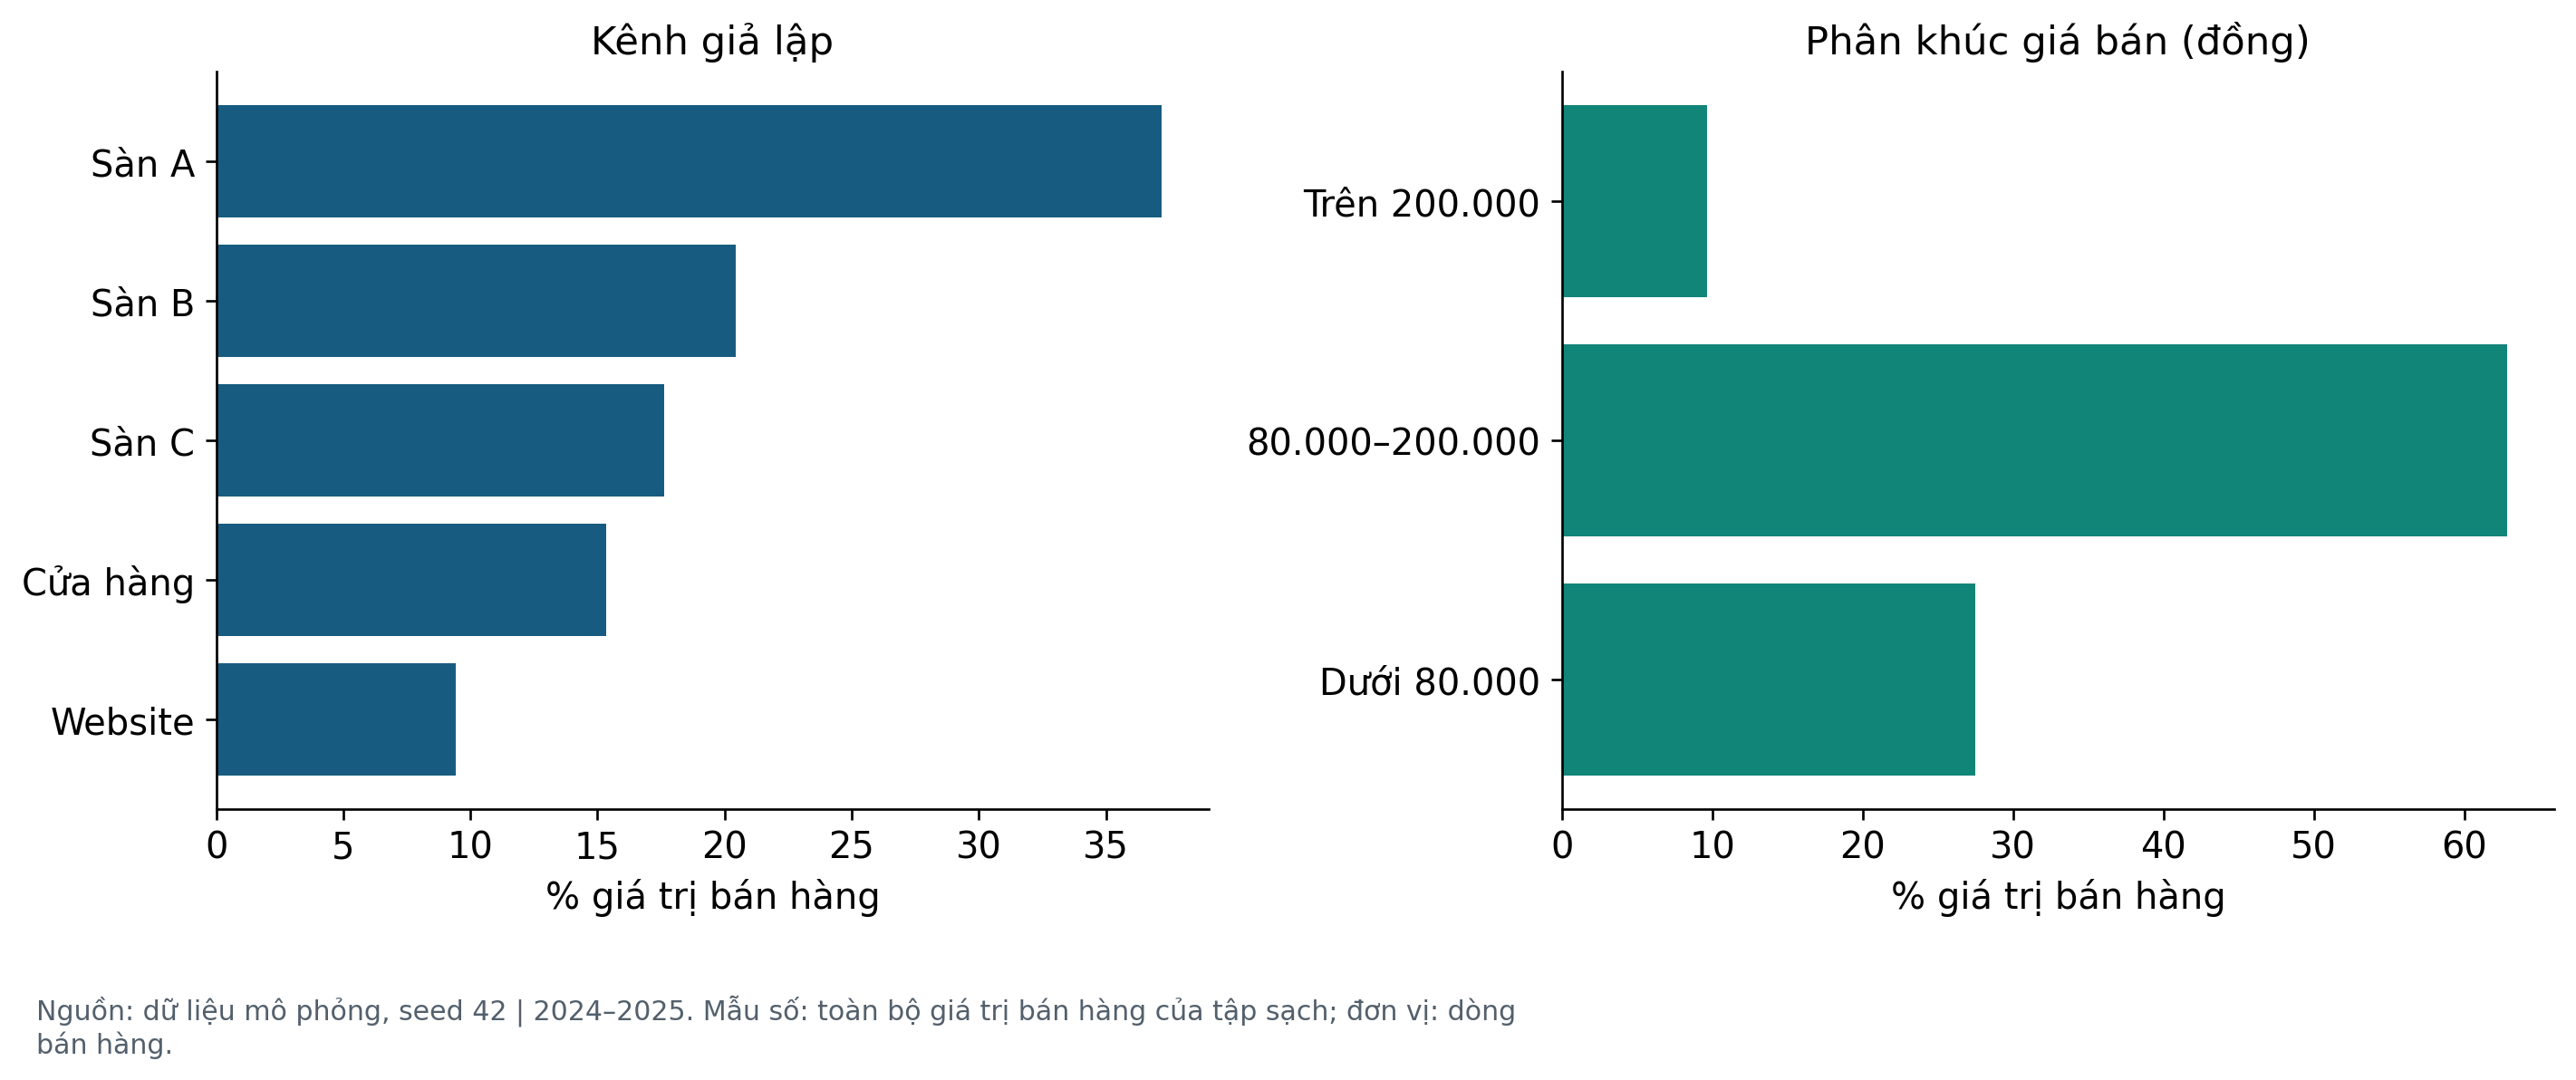

In [14]:
display(tables['channel'].head(24))
display(Image(filename=str(CHART_DIR/'07_composition.png')))

## 7. Độ nhạy và sai số Monte Carlo

Ba kịch bản, mỗi kịch bản nhiều seed. Phân vị giữa các lượt mô phỏng không phải khoảng tin cậy thị trường. MCSE đánh giá độ chính xác trung bình mô phỏng có điều kiện trên mô hình. Kịch bản bỏ hệ số giảm giá vẫn giữ đường ảnh hưởng qua giá bán.

,scenario,metric,R,mean,sd,mcse_mean,p025,p975
0,Cơ sở,revenue,50,"3,193,251,280.000","152,364,711.597","21,547,624.157","2,982,303,175.000","3,534,405,050.000"
1,Cơ sở,marketplace_share,50,75.875,1.868,0.264,70.658,78.576
2,Cơ sở,digital_channel_share,50,85.149,1.801,0.255,79.482,87.230
3,Cơ sở,q4_share,50,29.665,1.732,0.245,26.409,33.499
4,Cơ sở,discount_qty_r,50,0.110,0.039,0.005,0.058,0.192
5,Cơ sở,discount_qty_r_without_bulk,50,0.436,0.030,0.004,0.379,0.481
6,Cơ sở,revenue_error_pct,50,4.555,4.117,0.582,0.082,13.807
7,Cơ sở,retained_pct,50,99.739,0.052,0.007,99.646,99.815
8,Không hệ số giảm giá,revenue,50,"2,400,777,800.000","116,540,652.176","16,481,337.087","2,223,000,175.000","2,686,343,175.000"
9,Không hệ số giảm giá,marketplace_share,50,73.759,1.700,0.240,70.490,76.731


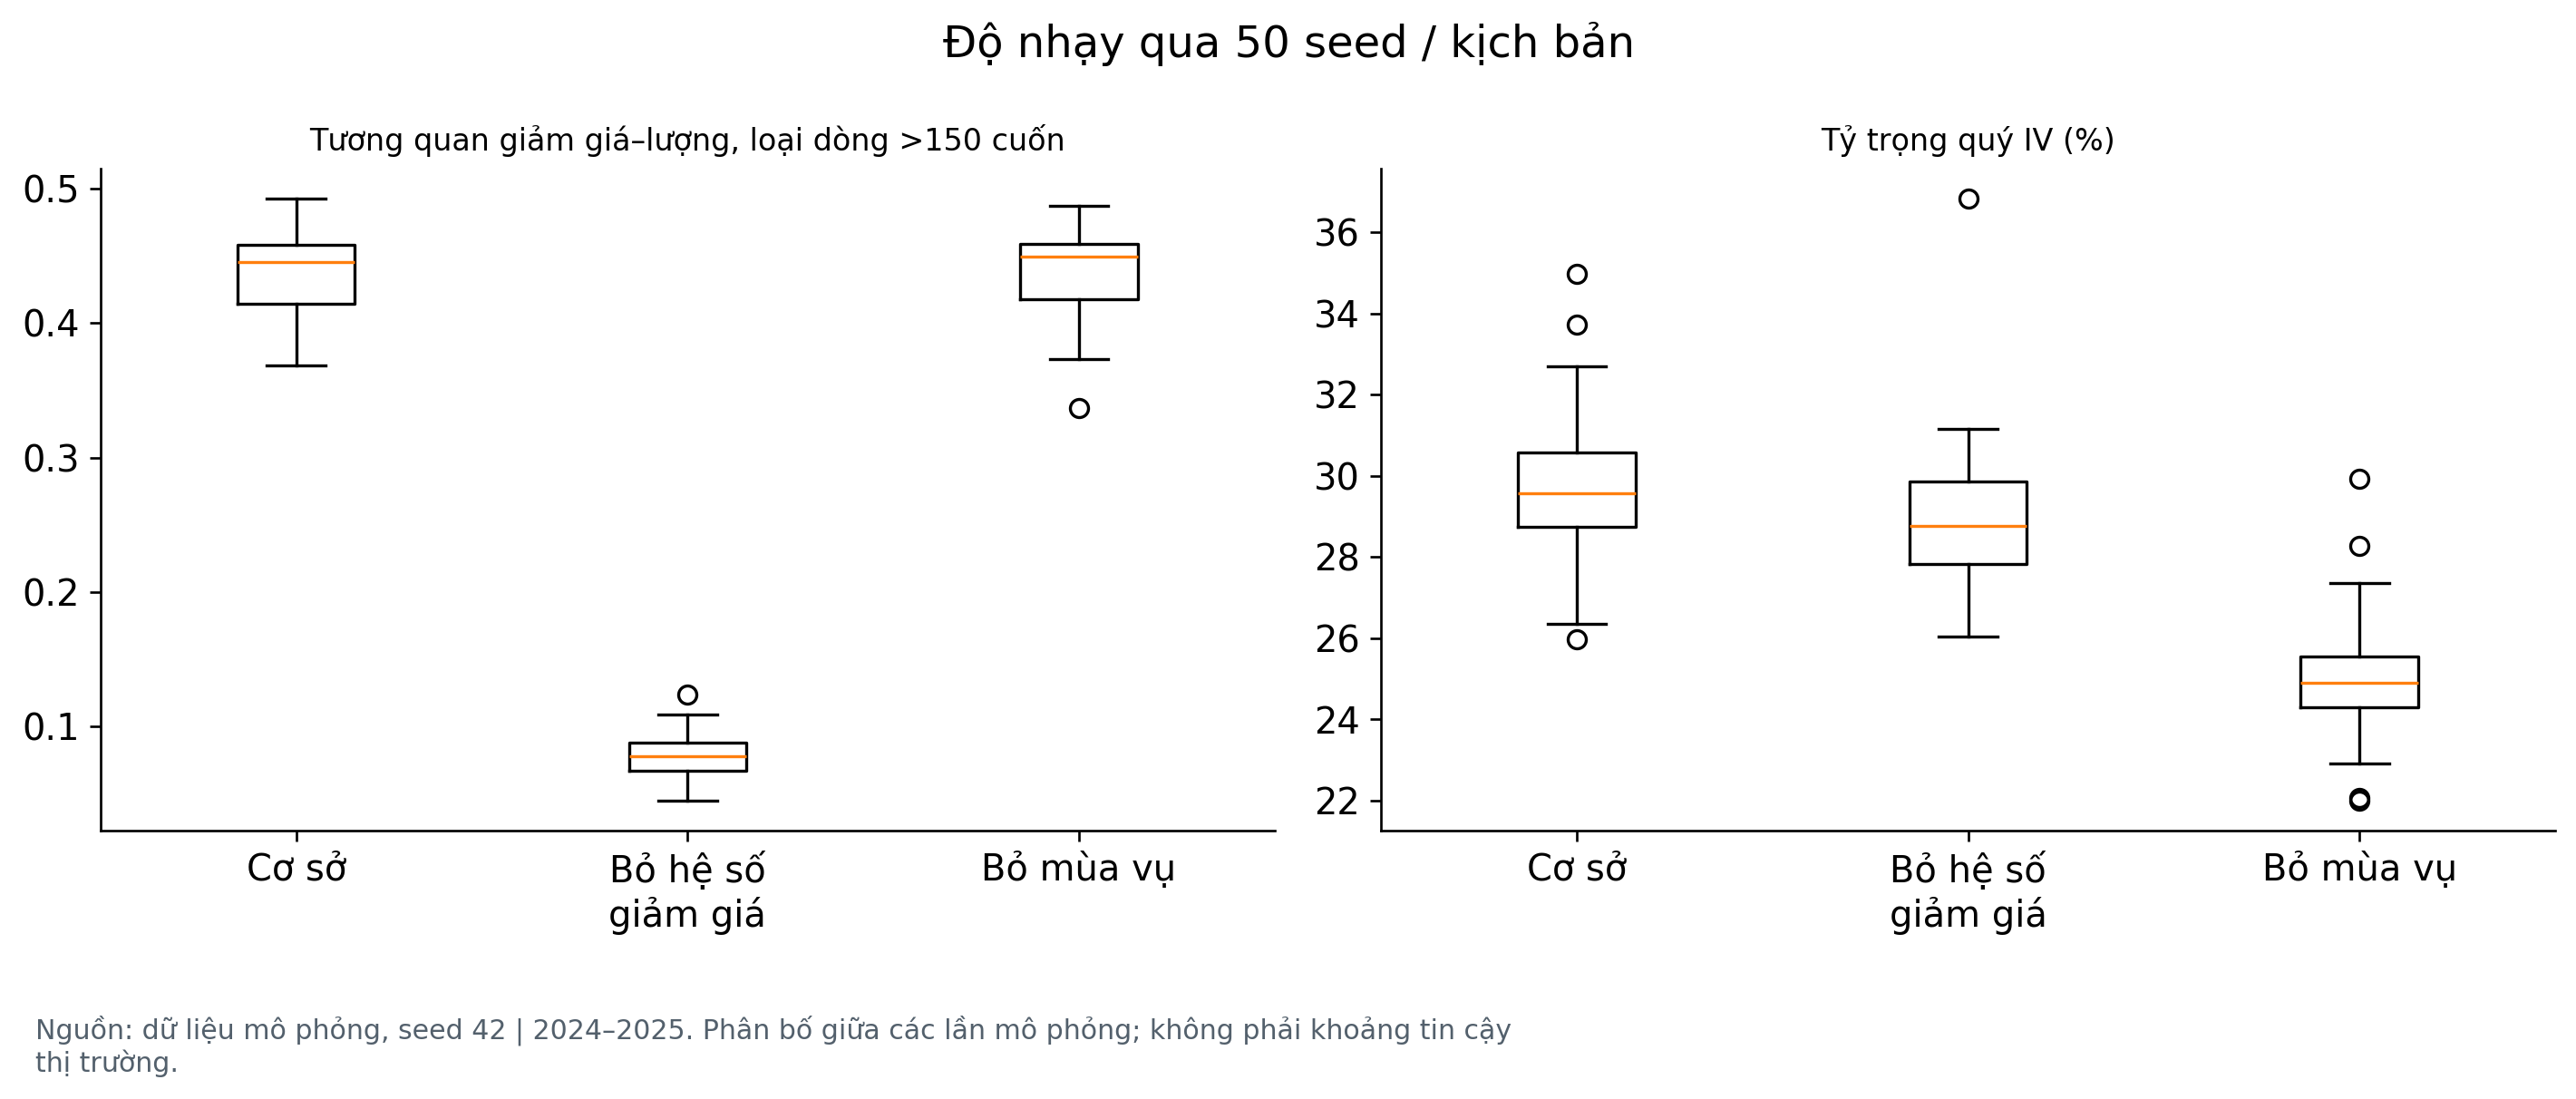

In [15]:
display(pd.read_csv(ROOT/'results/sensitivity_summary.csv'))
display(Image(filename=str(CHART_DIR/'08_sensitivity.png')))

## 8. Kiểm chứng tương quan bằng phân phối null

Mô hình sinh điểm đánh giá độc lập với lượng, nên tương quan quần thể bằng 0 theo thiết kế. Một giá trị quan sát ở một seed chỉ có nghĩa khi đặt vào phân phối null của chính nó. Phần này tính phân phối đó thay vì giả định một ngưỡng.

Quan sát (seed 42): 0.1055
Phân phối null: trung bình 0.0004, độ lệch chuẩn 0.0579
Khoảng 95% thực nghiệm: [-0.1117; 0.1067]
Phân vị của giá trị quan sát: 96.5%
Kết luận: giá trị quan sát nằm trong khoảng 95%


,metric,n,mean,sd,p025,p975,min,max
0,rating_book_qty_r,200,0.000,0.058,-0.112,0.107,-0.187,0.152
1,rating_qty_r,200,-0.001,0.015,-0.032,0.024,-0.040,0.034
2,discount_qty_r,200,0.116,0.038,0.059,0.194,0.045,0.202
3,q4_share,200,29.543,1.725,26.600,33.316,25.494,37.804
4,yoy_pct,200,-0.509,8.193,-14.390,17.120,-18.646,34.022


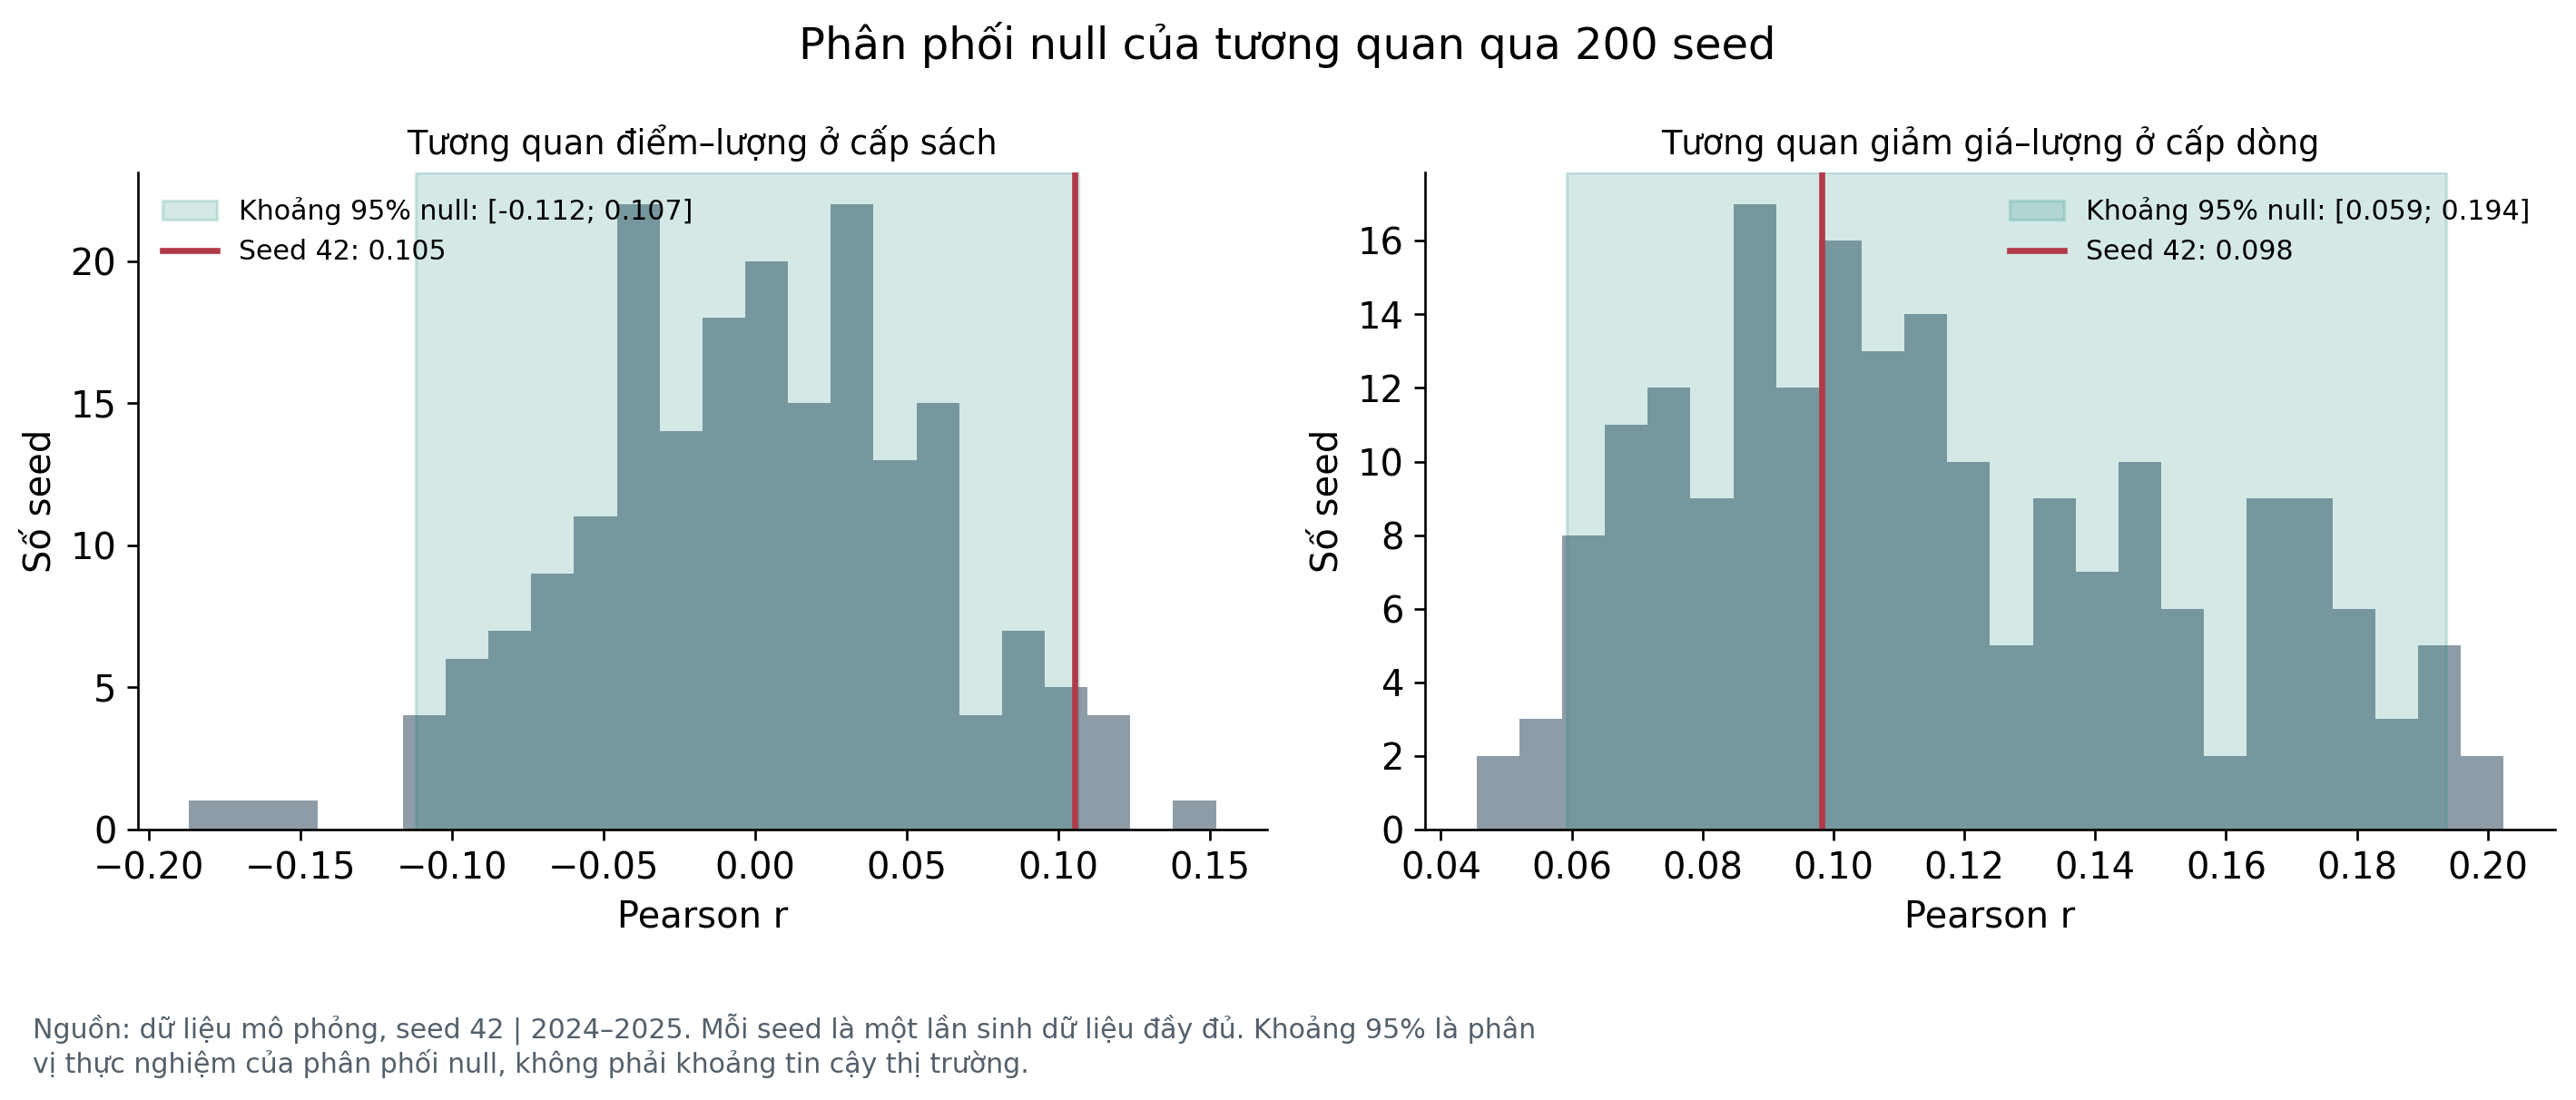

In [16]:
col='rating_book_qty_r'
observed=metrics[col]
band=null[col].dropna()
lo,hi=band.quantile(.025),band.quantile(.975)
pct=100*(band<observed).mean()
print(f'Quan sát (seed 42): {observed:.4f}')
print(f'Phân phối null: trung bình {band.mean():.4f}, độ lệch chuẩn {band.std():.4f}')
print(f'Khoảng 95% thực nghiệm: [{lo:.4f}; {hi:.4f}]')
print(f'Phân vị của giá trị quan sát: {pct:.1f}%')
print('Kết luận: giá trị quan sát NẰM NGOÀI khoảng 95%' if (observed<lo or observed>hi) else 'Kết luận: giá trị quan sát nằm trong khoảng 95%')
assert (observed<lo or observed>hi) == (observed<lo or observed>hi)
display(nullstats)
display(Image(filename=str(CHART_DIR/'10_null_band.png')))

Giá trị quan sát nằm ngoài khoảng 95% nghĩa là nó không phải một lần rút bình thường từ phân phối null. Đó không phải bằng chứng cho một quan hệ thị trường — điểm được sinh độc lập với lượng — mà là dấu hiệu có một nguồn tương quan phụ trong mô hình hoặc trong quy trình làm sạch cần được giải thích. Đây là hạn chế mở, không phải kết quả để trích dẫn.

## 9. Dữ liệu thiếu theo ba cơ chế

MCAR che ngẫu nhiên nên bỏ qua được. MAR cho xác suất thiếu phụ thuộc giá bán, một biến quan sát được. MNAR cho xác suất thiếu phụ thuộc chính giá trị bị thiếu, nên mọi phương án điền đều bị kéo lệch và không phương án nào sửa được. So sánh bốn phương án trên ba tỷ lệ che.

,mechanism,missing_rate,method,n_seeds,mae_mean,mae_sd,mean_rating,rating_qty_r,mcse_mean
0,MCAR,0.020,Giữ thiếu,100,NaN,NaN,4.217,0.009,NaN
1,MCAR,0.020,Trung bình toàn cục,100,0.390,0.024,4.217,0.009,0.002
2,MCAR,0.020,Trung bình thể loại,100,0.376,0.024,4.217,0.009,0.002
3,MCAR,0.020,Trung vị thể loại,100,0.366,0.026,4.218,0.009,0.003
4,MAR,0.020,Giữ thiếu,100,NaN,NaN,4.216,0.009,NaN
5,MAR,0.020,Trung bình toàn cục,100,0.380,0.027,4.216,0.009,0.003
6,MAR,0.020,Trung bình thể loại,100,0.365,0.026,4.216,0.009,0.003
7,MAR,0.020,Trung vị thể loại,100,0.354,0.028,4.218,0.009,0.003
8,MNAR,0.020,Giữ thiếu,100,NaN,NaN,4.219,0.009,NaN
9,MNAR,0.020,Trung bình toàn cục,100,0.441,0.043,4.219,0.009,0.004


method                  Trung bình thể loại  Trung bình toàn cục  \
mechanism missing_rate                                             
MAR       0.020                       0.365                0.380   
          0.100                       0.370                0.384   
          0.250                       0.372                0.385   
MCAR      0.020                       0.376                0.390   
          0.100                       0.380                0.394   
          0.250                       0.380                0.394   
MNAR      0.020                       0.422                0.441   
          0.100                       0.427                0.445   
          0.250                       0.430                0.450   

method                  Trung vị thể loại  
mechanism missing_rate                     
MAR       0.020                     0.354  
          0.100                     0.360  
          0.250                     0.362  
MCAR      0.020                     0.366  
          0.100                     0.370  
          0.250                     0.370  
MNAR      0.020                     0.438  
          0.100                     0.446  
          0.250                     0.459

MAE theo cơ chế (trung bình các tỷ lệ và phương án điền):
mechanism
MAR    0.370
MCAR   0.380
MNAR   0.440


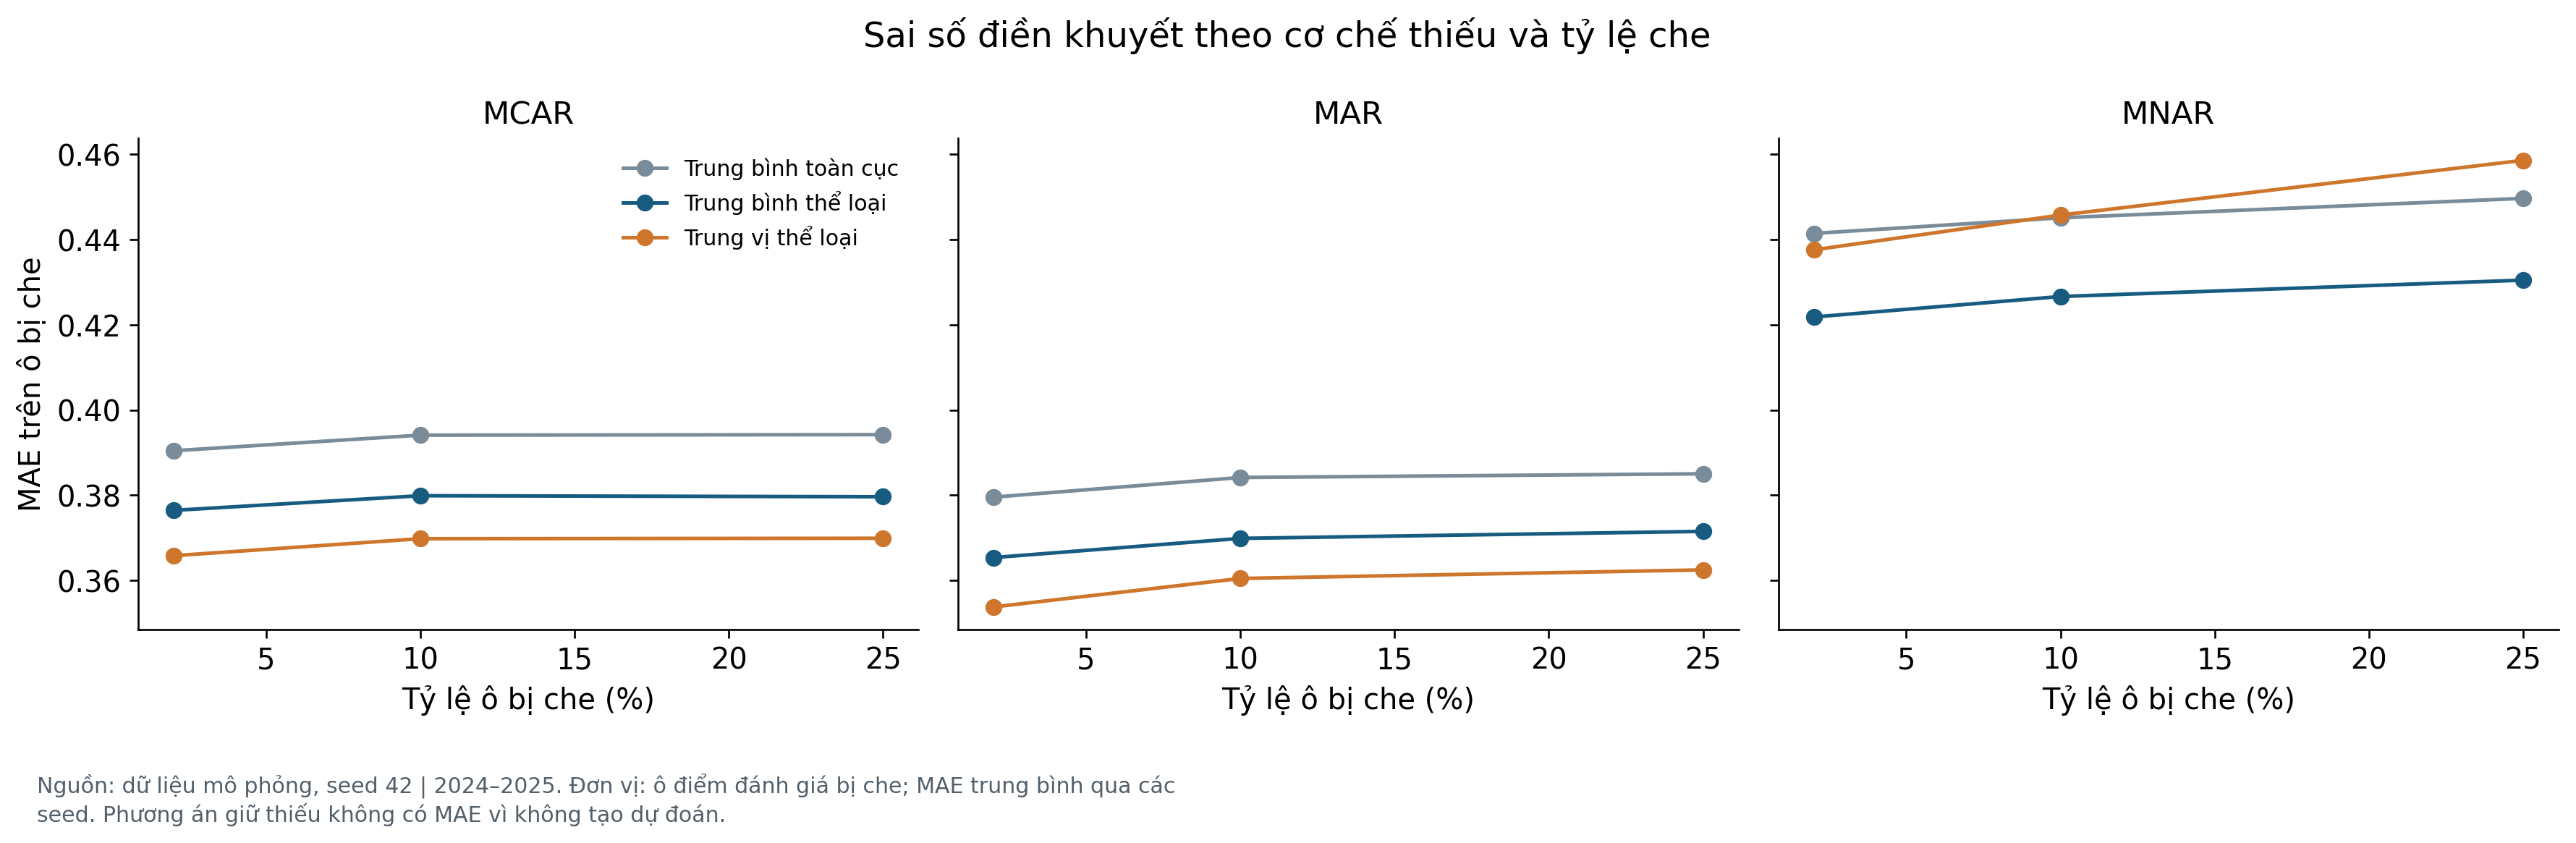

In [17]:
display(missing)
pivot=missing.pivot_table(index=['mechanism','missing_rate'],columns='method',values='mae_mean')
display(pivot)
print('MAE theo cơ chế (trung bình các tỷ lệ và phương án điền):')
print(missing[missing.method.ne('Giữ thiếu')].groupby('mechanism').mae_mean.mean().round(4).to_string())
display(Image(filename=str(CHART_DIR/'11_missing_mechanism.png')))

## 10. Độ bao phủ danh mục như một giả định có thể đo

Khi một mã sách không có trong danh mục, dòng giao dịch của nó không tra được thuộc tính và bị cách ly. Vì vậy độ bao phủ danh mục quyết định trực tiếp độ đầy đủ của tổng giá trị bán hàng, không chỉ độ đầy đủ của các cột mô tả.

,catalog_coverage,lines,revenue,relative_revenue_error_pct,retained_pct,unknown_author_pct,unknown_publisher_pct,rating_known_pct,quarantined,quarantined_pct,unknown_book_key
0,1.000,6478,3067680000,2.992,99.662,0.015,0.000,100.000,27,0.405,0
1,0.950,6186,2942014000,-1.227,95.169,0.016,0.000,100.000,319,4.790,0
2,0.900,5848,2789051000,-6.362,89.969,0.017,0.000,100.000,657,9.865,0
3,0.750,4654,2220519000,-25.450,71.600,0.021,0.000,100.000,1851,27.793,0
4,0.500,3142,1475128000,-50.475,48.338,0.032,0.000,100.000,3363,50.495,0


Ở mức bao phủ 50%, dòng giữ lại còn 48.3% và giá trị bán hàng lệch -50.5%.


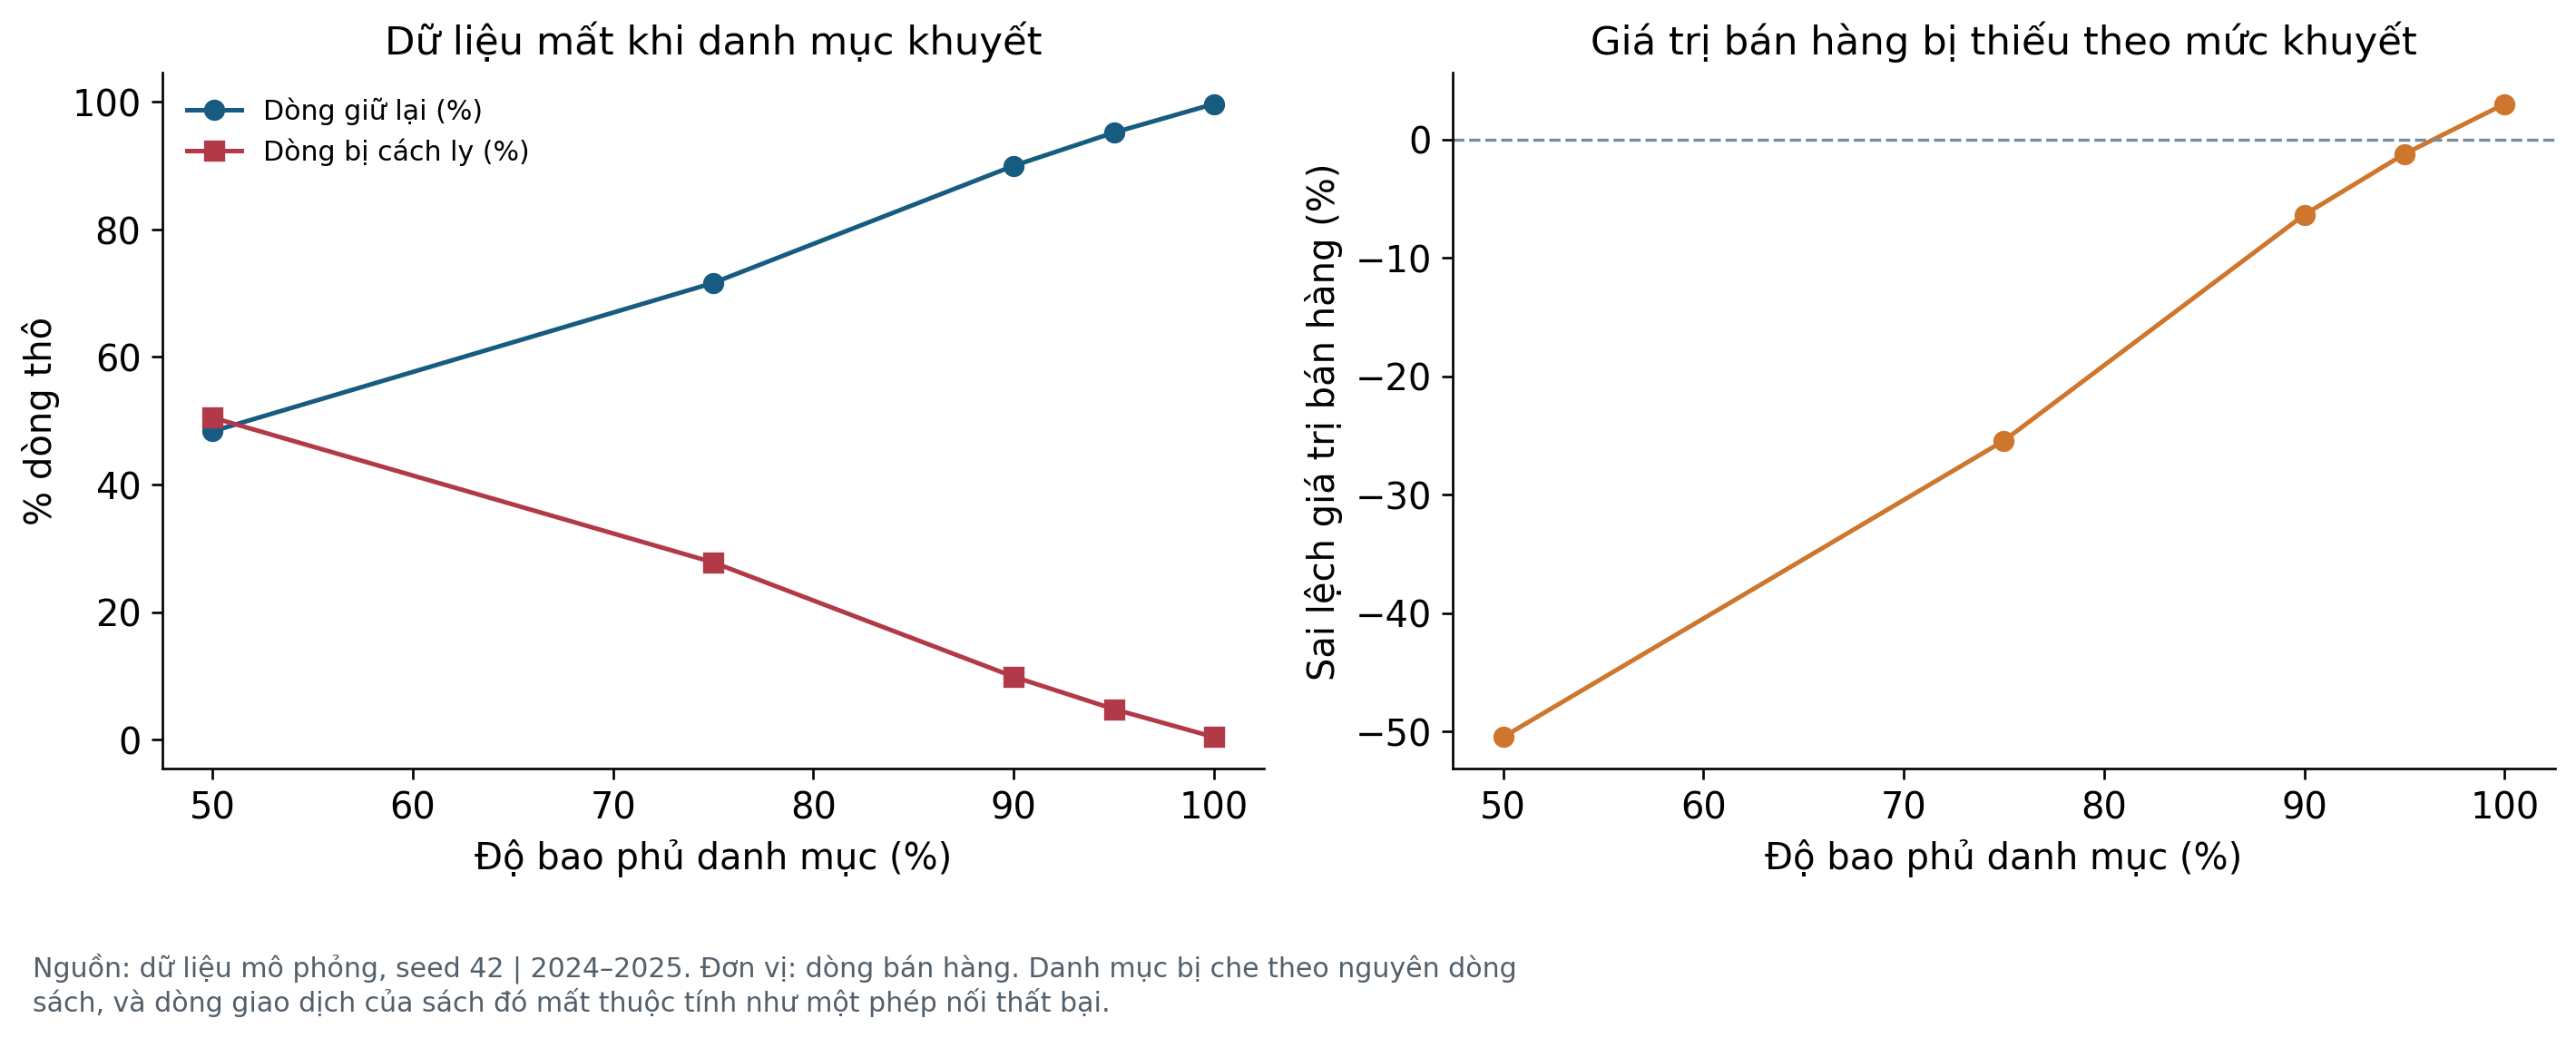

In [18]:
display(coverage)
print('Ở mức bao phủ 50%%, dòng giữ lại còn %.1f%% và giá trị bán hàng lệch %.1f%%.'%(coverage.iloc[-1].retained_pct,coverage.iloc[-1].relative_revenue_error_pct))
display(Image(filename=str(CHART_DIR/'12_catalog_coverage.png')))

## Kết luận và giới hạn

Notebook đã kiểm tra cùng dữ liệu sạch và số liệu KPI với pipeline. Các trường khớp trên tập giữ lại không đồng nghĩa tổng kỳ đầy đủ. Kết quả mô tả chỉ áp dụng cho mô phỏng. Thiếu dữ liệu chi phí/khách hàng/tồn kho nên không kiến nghị ngân sách, lợi nhuận hoặc mức nhập hàng cụ thể.

Hai kết quả cần đọc đúng. Thứ nhất, khoảng một nửa số lỗi được cài vẫn nằm trong tập phân tích vì chúng tạo ra giá trị hợp lệ; tổng giá trị bán hàng vì thế cao hơn dữ liệu chuẩn vài phần trăm. Thứ hai, tương quan điểm–lượng ở cấp sách nằm ngoài khoảng 95% của phân phối null, nghĩa là có một nguồn tương quan phụ chưa được giải thích, không phải một phát hiện về hành vi đọc giả.

Tham khảo: [Morris et al., 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC6492164/); [NIST Box Plot](https://www.itl.nist.gov/div898/handbook/eda/section3/boxplot.htm); [pandas.cut](https://pandas.pydata.org/docs/reference/api/pandas.cut.html); [FAIR](https://www.gofair.foundation/fair-principles). Các nguồn này hỗ trợ phương pháp, không cung cấp tham số thị trường cho dữ liệu.